In [166]:
import yfinance as yf
import pandas as pd
import numpy as np

assets = [
    "XLB", "XLE", "XLF",
    "XLI", "XLK", "XLP",
    "XLU", "XLV", "XLY"
]

state_tickers = [
    "SPY",
    "^VIX"
]

all_tickers = assets + state_tickers

In [167]:
data = yf.download(
    all_tickers,
    start="2010-01-01",
    auto_adjust=False,
    progress=False
)

print(data.shape)
print(data.head())
print(data.tail())

(4224, 66)
Price       Adj Close                                                       \
Ticker            SPY        XLB        XLE       XLF        XLI       XLK   
Date                                                                         
2010-01-04  84.368942  11.916908  17.043320  8.879748  20.815491  9.356694   
2010-01-05  84.592300  11.955438  17.182425  9.042955  20.888998  9.344634   
2010-01-06  84.651855  12.158608  17.388180  9.061088  20.933092  9.240088   
2010-01-07  85.009201  12.064029  17.362104  9.254522  21.160955  9.203898   
2010-01-08  85.292099  12.232167  17.475122  9.200121  21.499054  9.264210   

Price                                                  ...      Volume  \
Ticker            XLP       XLU        XLV        XLY  ...         XLB   
Date                                                   ...               
2010-01-04  17.019968  8.765264  23.788490  12.257140  ...  15135000.0   
2010-01-05  17.026346  8.660913  23.555197  12.302091  ...  17678400

In [168]:
data.to_csv("../data/raw/yahoo_market_data.csv")

In [169]:
print(data.info())

<class 'pandas.DataFrame'>
DatetimeIndex: 4224 entries, 2010-01-04 to 2026-10-15
Data columns (total 66 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Adj Close, SPY)   4221 non-null   float64
 1   (Adj Close, XLB)   4221 non-null   float64
 2   (Adj Close, XLE)   4221 non-null   float64
 3   (Adj Close, XLF)   4221 non-null   float64
 4   (Adj Close, XLI)   4221 non-null   float64
 5   (Adj Close, XLK)   4221 non-null   float64
 6   (Adj Close, XLP)   4221 non-null   float64
 7   (Adj Close, XLU)   4221 non-null   float64
 8   (Adj Close, XLV)   4221 non-null   float64
 9   (Adj Close, XLY)   4221 non-null   float64
 10  (Adj Close, ^VIX)  4224 non-null   float64
 11  (Close, SPY)       4221 non-null   float64
 12  (Close, XLB)       4221 non-null   float64
 13  (Close, XLE)       4221 non-null   float64
 14  (Close, XLF)       4221 non-null   float64
 15  (Close, XLI)       4221 non-null   float64
 16  (Close, XLK)     

In [170]:
print(data.isnull().sum())

Price      Ticker
Adj Close  SPY       3
           XLB       3
           XLE       3
           XLF       3
           XLI       3
                    ..
Volume     XLP       3
           XLU       3
           XLV       3
           XLY       3
           ^VIX      0
Length: 66, dtype: int64


In [171]:
print(data.index.min())
print(data.index.max())

2010-01-04 00:00:00
2026-10-15 00:00:00


In [172]:
import pandas as pd
import yfinance as yf

try:
    data
except NameError:
    try:
        data = pd.read_csv("../data/raw/yahoo_market_data.csv", header=[0, 1], index_col=0, parse_dates=True)
    except FileNotFoundError:
        assets = [
            "XLB", "XLE", "XLF",
            "XLI", "XLK", "XLP",
            "XLU", "XLV", "XLY"
        ]

        state_tickers = [
            "SPY",
            "^VIX"
        ]

        all_tickers = assets + state_tickers
        data = yf.download(
            all_tickers,
            start="2010-01-01",
            auto_adjust=False,
            progress=False
        )

print(data.columns)

MultiIndex([('Adj Close',  'SPY'),
            ('Adj Close',  'XLB'),
            ('Adj Close',  'XLE'),
            ('Adj Close',  'XLF'),
            ('Adj Close',  'XLI'),
            ('Adj Close',  'XLK'),
            ('Adj Close',  'XLP'),
            ('Adj Close',  'XLU'),
            ('Adj Close',  'XLV'),
            ('Adj Close',  'XLY'),
            ('Adj Close', '^VIX'),
            (    'Close',  'SPY'),
            (    'Close',  'XLB'),
            (    'Close',  'XLE'),
            (    'Close',  'XLF'),
            (    'Close',  'XLI'),
            (    'Close',  'XLK'),
            (    'Close',  'XLP'),
            (    'Close',  'XLU'),
            (    'Close',  'XLV'),
            (    'Close',  'XLY'),
            (    'Close', '^VIX'),
            (     'High',  'SPY'),
            (     'High',  'XLB'),
            (     'High',  'XLE'),
            (     'High',  'XLF'),
            (     'High',  'XLI'),
            (     'High',  'XLK'),
            (     'H

In [173]:
prices = data["Adj Close"].copy()

In [174]:
print(prices.head())
print(prices.shape)
print(prices.isnull().sum())

Ticker            SPY        XLB        XLE       XLF        XLI       XLK  \
Date                                                                         
2010-01-04  84.368942  11.916908  17.043320  8.879748  20.815491  9.356694   
2010-01-05  84.592300  11.955438  17.182425  9.042955  20.888998  9.344634   
2010-01-06  84.651855  12.158608  17.388180  9.061088  20.933092  9.240088   
2010-01-07  85.009201  12.064029  17.362104  9.254522  21.160955  9.203898   
2010-01-08  85.292099  12.232167  17.475122  9.200121  21.499054  9.264210   

Ticker            XLP       XLU        XLV        XLY       ^VIX  
Date                                                              
2010-01-04  17.019968  8.765264  23.788490  12.257140  20.040001  
2010-01-05  17.026346  8.660913  23.555197  12.302091  19.350000  
2010-01-06  17.013584  8.711679  23.796019  12.318428  19.160000  
2010-01-07  17.013584  8.672195  23.878801  12.420573  19.059999  
2010-01-08  16.956146  8.663732  23.916426  12.4164

In [175]:
missing_rows = prices[prices.isnull().any(axis=1)]

print(missing_rows)

Ticker      SPY  XLB  XLE  XLF  XLI  XLK  XLP  XLU  XLV  XLY   ^VIX
Date                                                               
2026-05-25  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  16.59
2026-09-07  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  15.30
2026-10-15  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  17.48


In [176]:
assets = [
    "XLB", "XLE", "XLF",
    "XLI", "XLK", "XLP",
    "XLU", "XLV", "XLY"
]

In [177]:
asset_prices = prices[assets].copy()

In [178]:
print(asset_prices.head())
print(asset_prices.shape)

Ticker            XLB        XLE       XLF        XLI       XLK        XLP  \
Date                                                                         
2010-01-04  11.916908  17.043320  8.879748  20.815491  9.356694  17.019968   
2010-01-05  11.955438  17.182425  9.042955  20.888998  9.344634  17.026346   
2010-01-06  12.158608  17.388180  9.061088  20.933092  9.240088  17.013584   
2010-01-07  12.064029  17.362104  9.254522  21.160955  9.203898  17.013584   
2010-01-08  12.232167  17.475122  9.200121  21.499054  9.264210  16.956146   

Ticker           XLU        XLV        XLY  
Date                                        
2010-01-04  8.765264  23.788490  12.257140  
2010-01-05  8.660913  23.555197  12.302091  
2010-01-06  8.711679  23.796019  12.318428  
2010-01-07  8.672195  23.878801  12.420573  
2010-01-08  8.663732  23.916426  12.416488  
(4224, 9)


In [179]:
spy_price = prices["SPY"].copy()

print(spy_price.head())

Date
2010-01-04    84.368942
2010-01-05    84.592300
2010-01-06    84.651855
2010-01-07    85.009201
2010-01-08    85.292099
Name: SPY, dtype: float64


In [180]:
vix = prices["^VIX"].copy()

print(vix.head())

Date
2010-01-04    20.040001
2010-01-05    19.350000
2010-01-06    19.160000
2010-01-07    19.059999
2010-01-08    18.129999
Name: ^VIX, dtype: float64


In [181]:
print("Portfolio assets:")
print(asset_prices.head())

print("\nAsset price shape:")
print(asset_prices.shape)

print("\nSPY:")
print(spy_price.head())

print("\nVIX:")
print(vix.head())

print("\nMissing rows:")
print(prices[prices.isnull().any(axis=1)])

Portfolio assets:
Ticker            XLB        XLE       XLF        XLI       XLK        XLP  \
Date                                                                         
2010-01-04  11.916908  17.043320  8.879748  20.815491  9.356694  17.019968   
2010-01-05  11.955438  17.182425  9.042955  20.888998  9.344634  17.026346   
2010-01-06  12.158608  17.388180  9.061088  20.933092  9.240088  17.013584   
2010-01-07  12.064029  17.362104  9.254522  21.160955  9.203898  17.013584   
2010-01-08  12.232167  17.475122  9.200121  21.499054  9.264210  16.956146   

Ticker           XLU        XLV        XLY  
Date                                        
2010-01-04  8.765264  23.788490  12.257140  
2010-01-05  8.660913  23.555197  12.302091  
2010-01-06  8.711679  23.796019  12.318428  
2010-01-07  8.672195  23.878801  12.420573  
2010-01-08  8.663732  23.916426  12.416488  

Asset price shape:
(4224, 9)

SPY:
Date
2010-01-04    84.368942
2010-01-05    84.592300
2010-01-06    84.651855
2010-01

In [182]:
missing_rows = prices[prices.isnull().any(axis=1)]

print("Number of rows containing missing values:",
      len(missing_rows))

print("\nDates with missing values:")
print(missing_rows.index.tolist())

print("\nMissing values on each affected date:")
for date, row in missing_rows.iterrows():
    missing = row[row.isna()].index.tolist()
    print(date.date(), "->", missing)

Number of rows containing missing values: 3

Dates with missing values:
[Timestamp('2026-05-25 00:00:00'), Timestamp('2026-09-07 00:00:00'), Timestamp('2026-10-15 00:00:00')]

Missing values on each affected date:
2026-05-25 -> ['SPY', 'XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']
2026-09-07 -> ['SPY', 'XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']
2026-10-15 -> ['SPY', 'XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']


In [183]:
#Keep only dates where all 11 required serieare available
clean_prices = prices.dropna().copy()

print("Before cleaning:", prices.shape)
print("After cleaning:", clean_prices.shape)

print("\nMissing values after cleaning:")
print(clean_prices.isnull().sum())

print("\nData range:")
print(clean_prices.index.min())
print(clean_prices.index.max())
      

Before cleaning: (4224, 11)
After cleaning: (4221, 11)

Missing values after cleaning:
Ticker
SPY     0
XLB     0
XLE     0
XLF     0
XLI     0
XLK     0
XLP     0
XLU     0
XLV     0
XLY     0
^VIX    0
dtype: int64

Data range:
2010-01-04 00:00:00
2026-10-14 00:00:00


In [184]:
assets = [
    "XLB", "XLE", "XLF",
    "XLI", "XLK", "XLP",
    "XLU", "XLV", "XLY"
]

asset_prices = clean_prices[assets].copy()

spy_price = clean_prices["SPY"].copy()
vix = clean_prices["^VIX"].copy()

In [185]:
print("Asset prices:", asset_prices.shape)
print("SPY price:", spy_price.shape)
print("VIX price:", vix.shape)

print("\nAsset mssing values:")
print(asset_prices.isnull().sum())

Asset prices: (4221, 9)
SPY price: (4221,)
VIX price: (4221,)

Asset mssing values:
Ticker
XLB    0
XLE    0
XLF    0
XLI    0
XLK    0
XLP    0
XLU    0
XLV    0
XLY    0
dtype: int64


In [186]:
prices.head()

Ticker,SPY,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,^VIX
Date,,,,,,,,,,,
2010-01-04,84.368942,11.916908,17.043320,8.879748,20.815491,9.356694,17.019968,8.765264,23.788490,12.257140,20.040001
2010-01-05,84.592300,11.955438,17.182425,9.042955,20.888998,9.344634,17.026346,8.660913,23.555197,12.302091,19.350000
2010-01-06,84.651855,12.158608,17.388180,9.061088,20.933092,9.240088,17.013584,8.711679,23.796019,12.318428,19.160000
2010-01-07,85.009201,12.064029,17.362104,9.254522,21.160955,9.203898,17.013584,8.672195,23.878801,12.420573,19.059999
2010-01-08,85.292099,12.232167,17.475122,9.200121,21.499054,9.264210,16.956146,8.663732,23.916426,12.416488,18.129999


In [187]:
prices.shape

(4224, 11)

In [188]:
prices.index

DatetimeIndex(['2010-01-04', '2010-01-05', '2010-01-06', '2010-01-07',
               '2010-01-08', '2010-01-11', '2010-01-12', '2010-01-13',
               '2010-01-14', '2010-01-15',
               ...
               '2026-10-02', '2026-10-05', '2026-10-06', '2026-10-07',
               '2026-10-08', '2026-10-09', '2026-10-12', '2026-10-13',
               '2026-10-14', '2026-10-15'],
              dtype='datetime64[s]', name='Date', length=4224, freq=None)

In [189]:
returns = np.log(prices / prices.shift(1))

In [190]:
returns.head()

Ticker,SPY,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,^VIX
Date,,,,,,,,,,,
2010-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-05,0.002644,0.003228,0.008129,0.018213,0.003525,-0.001290,0.000375,-0.011976,-0.009855,0.003661,-0.035038
2010-01-06,0.000704,0.016851,0.011904,0.002003,0.002109,-0.011251,-0.000750,0.005844,0.010172,0.001327,-0.009868
2010-01-07,0.004212,-0.007809,-0.001501,0.021123,0.010826,-0.003924,0.000000,-0.004543,0.003473,0.008258,-0.005233
2010-01-08,0.003322,0.013841,0.006488,-0.005896,0.015851,0.006531,-0.003382,-0.000976,0.001574,-0.000329,-0.050024


In [191]:
returns = returns.dropna()

In [192]:
returns.head()

Ticker,SPY,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,^VIX
Date,,,,,,,,,,,
2010-01-05,0.002644,0.003228,0.008129,0.018213,0.003525,-0.001290,0.000375,-0.011976,-0.009855,0.003661,-0.035038
2010-01-06,0.000704,0.016851,0.011904,0.002003,0.002109,-0.011251,-0.000750,0.005844,0.010172,0.001327,-0.009868
2010-01-07,0.004212,-0.007809,-0.001501,0.021123,0.010826,-0.003924,0.000000,-0.004543,0.003473,0.008258,-0.005233
2010-01-08,0.003322,0.013841,0.006488,-0.005896,0.015851,0.006531,-0.003382,-0.000976,0.001574,-0.000329,-0.050024
2010-01-11,0.001395,-0.005456,-0.001328,0.000656,0.010881,-0.003913,0.002631,0.010363,0.005648,-0.001977,-0.032514


In [193]:
print(returns.columns.tolist())
print(returns.shape)


['SPY', 'XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY', '^VIX']
(4218, 11)


In [194]:
sector_tickers = [
    "XLB", "XLE", "XLF",
    "XLI", "XLK", "XLP",
    "XLU", "XLV", "XLY"
]

sector_returns = returns[sector_tickers].copy()

In [195]:
sector_returns.head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2010-01-05,0.003228,0.008129,0.018213,0.003525,-0.001290,0.000375,-0.011976,-0.009855,0.003661
2010-01-06,0.016851,0.011904,0.002003,0.002109,-0.011251,-0.000750,0.005844,0.010172,0.001327
2010-01-07,-0.007809,-0.001501,0.021123,0.010826,-0.003924,0.000000,-0.004543,0.003473,0.008258
2010-01-08,0.013841,0.006488,-0.005896,0.015851,0.006531,-0.003382,-0.000976,0.001574,-0.000329
2010-01-11,-0.005456,-0.001328,0.000656,0.010881,-0.003913,0.002631,0.010363,0.005648,-0.001977


In [196]:
sector_returns.shape

(4218, 9)

In [197]:
market_features = returns[["SPY", "^VIX"]].copy()
market_features.head()

Ticker,SPY,^VIX
Date,,
2010-01-05,0.002644,-0.035038
2010-01-06,0.000704,-0.009868
2010-01-07,0.004212,-0.005233
2010-01-08,0.003322,-0.050024
2010-01-11,0.001395,-0.032514


In [198]:
sector_returns.isna().sum()

Ticker
XLB    0
XLE    0
XLF    0
XLI    0
XLK    0
XLP    0
XLU    0
XLV    0
XLY    0
dtype: int64

In [199]:
np.isinf(sector_returns).sum()

Ticker
XLB    0
XLE    0
XLF    0
XLI    0
XLK    0
XLP    0
XLU    0
XLV    0
XLY    0
dtype: int64

In [200]:
sector_returns.index.duplicated().sum()

np.int64(0)

In [201]:
sector_returns.index.is_monotonic_increasing

True

In [202]:
sector_returns.dtypes

Ticker
XLB    float64
XLE    float64
XLF    float64
XLI    float64
XLK    float64
XLP    float64
XLU    float64
XLV    float64
XLY    float64
dtype: object

In [203]:
sector_returns.min()

Ticker
XLB   -0.116628
XLE   -0.224910
XLF   -0.147449
XLI   -0.120408
XLK   -0.148663
XLP   -0.098668
XLU   -0.120561
XLV   -0.103818
XLY   -0.135460
dtype: float64

In [204]:
sector_returns.max()

Ticker
XLB    0.111184
XLE    0.148741
XLF    0.123603
XLI    0.119126
XLK    0.125978
XLP    0.081678
XLU    0.120388
XLV    0.074232
XLY    0.103351
dtype: float64

In [205]:
sector_returns.abs().max().sort_values(ascending=False)

Ticker
XLE    0.224910
XLK    0.148663
XLF    0.147449
XLY    0.135460
XLU    0.120561
XLI    0.120408
XLB    0.116628
XLV    0.103818
XLP    0.098668
dtype: float64

In [206]:
print("=== SECTOR RETURN DATA VALIDATION ===")
print("Observations:", sector_returns.shape[0])
print("Assets:", sector_returns.shape[1])
print("Start date:", sector_returns.index.min())
print("End date:", sector_returns.index.max())
print("Missing values:", sector_returns.isna().sum().sum())
print("Infinite values:", np.isinf(sector_returns.to_numpy()).sum())
print("Duplicate dates:", sector_returns.index.duplicated().sum())
print("Chronological:", sector_returns.index.is_monotonic_increasing)

=== SECTOR RETURN DATA VALIDATION ===
Observations: 4218
Assets: 9
Start date: 2010-01-05 00:00:00
End date: 2026-10-14 00:00:00
Missing values: 0
Infinite values: 0
Duplicate dates: 0
Chronological: True


In [207]:
summary_stats = sector_returns.describe().T
summary_stats

,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
XLB,4218.0,0.000337,0.013068,-0.116628,-0.006279,0.000728,0.007386,0.111184
XLE,4218.0,0.000331,0.017152,-0.224910,-0.007680,0.000675,0.008904,0.148741
XLF,4218.0,0.000434,0.013689,-0.147449,-0.005669,0.000763,0.007318,0.123603
XLI,4218.0,0.000491,0.012215,-0.120408,-0.005117,0.000881,0.006660,0.119126
XLK,4218.0,0.000707,0.013893,-0.148663,-0.005282,0.001203,0.007630,0.125978
XLP,4218.0,0.000389,0.008703,-0.098668,-0.003839,0.000577,0.005028,0.081678
XLU,4218.0,0.000368,0.010991,-0.120561,-0.005159,0.000943,0.006247,0.120388
XLV,4218.0,0.000480,0.010206,-0.103818,-0.004434,0.000678,0.005966,0.074232
XLY,4218.0,0.000525,0.012822,-0.135460,-0.005308,0.001229,0.007275,0.103351


In [208]:
summary_stats["skewness"] = sector_returns.skew()
summary_stats["kurtosis"] = sector_returns.kurt()

summary_stats

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Ticker,,,,,,,,,,
XLB,4218.0,0.000337,0.013068,-0.116628,-0.006279,0.000728,0.007386,0.111184,-0.393476,7.106500
XLE,4218.0,0.000331,0.017152,-0.224910,-0.007680,0.000675,0.008904,0.148741,-0.822736,15.061907
XLF,4218.0,0.000434,0.013689,-0.147449,-0.005669,0.000763,0.007318,0.123603,-0.511096,12.077409
XLI,4218.0,0.000491,0.012215,-0.120408,-0.005117,0.000881,0.006660,0.119126,-0.481890,10.576617
XLK,4218.0,0.000707,0.013893,-0.148663,-0.005282,0.001203,0.007630,0.125978,-0.294357,9.290458
XLP,4218.0,0.000389,0.008703,-0.098668,-0.003839,0.000577,0.005028,0.081678,-0.444405,12.544089
XLU,4218.0,0.000368,0.010991,-0.120561,-0.005159,0.000943,0.006247,0.120388,-0.309320,14.614191
XLV,4218.0,0.000480,0.010206,-0.103818,-0.004434,0.000678,0.005966,0.074232,-0.377722,7.434413
XLY,4218.0,0.000525,0.012822,-0.135460,-0.005308,0.001229,0.007275,0.103351,-0.557203,8.155095


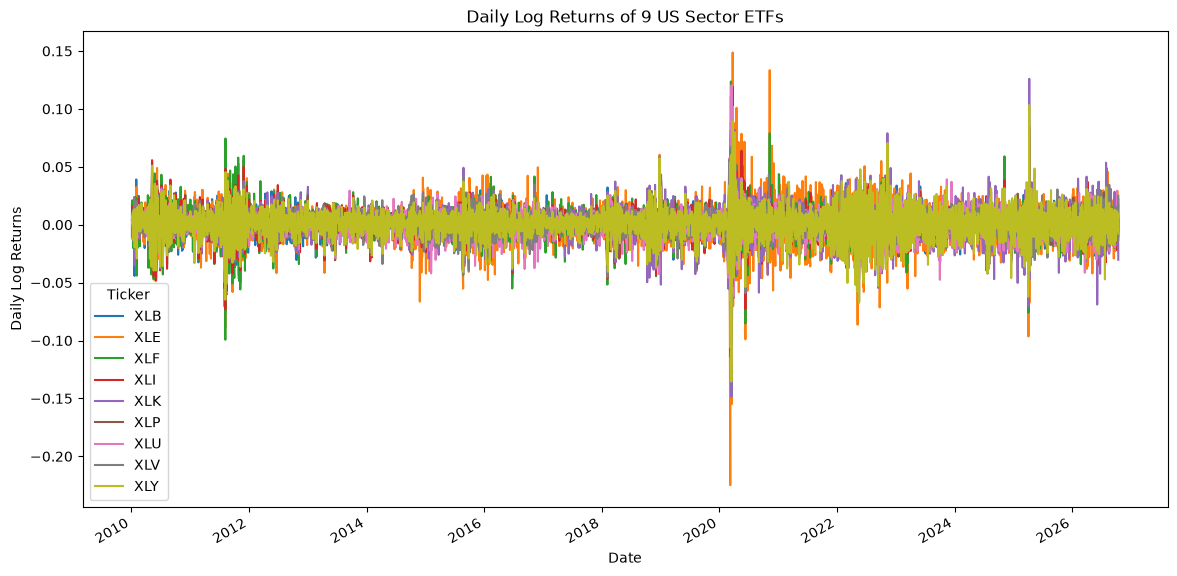

In [209]:
import matplotlib.pyplot as plt

sector_returns.plot(
    figsize=(14,7),
    title = "Daily Log Returns of 9 US Sector ETFs"
)

plt.xlabel("Date")
plt.ylabel("Daily Log Returns")
plt.show()

In [210]:
correlation_matrix = sector_returns.corr()
correlation_matrix

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,1.000000,0.695751,0.810364,0.873740,0.693996,0.636399,0.523081,0.693640,0.749778
XLE,0.695751,1.000000,0.681585,0.682438,0.481581,0.450802,0.395816,0.500739,0.521212
XLF,0.810364,0.681585,1.000000,0.862308,0.673321,0.624055,0.502528,0.694590,0.751066
XLI,0.873740,0.682438,0.862308,1.000000,0.752596,0.653246,0.553663,0.716709,0.797986
XLK,0.693996,0.481581,0.673321,0.752596,1.000000,0.521903,0.424669,0.635887,0.821297
XLP,0.636399,0.450802,0.624055,0.653246,0.521903,1.000000,0.681104,0.712073,0.601885
XLU,0.523081,0.395816,0.502528,0.553663,0.424669,0.681104,1.000000,0.551370,0.455019
XLV,0.693640,0.500739,0.694590,0.716709,0.635887,0.712073,0.551370,1.000000,0.663605
XLY,0.749778,0.521212,0.751066,0.797986,0.821297,0.601885,0.455019,0.663605,1.000000


In [211]:
np.allclose(correlation_matrix.values, correlation_matrix.values.T)

True

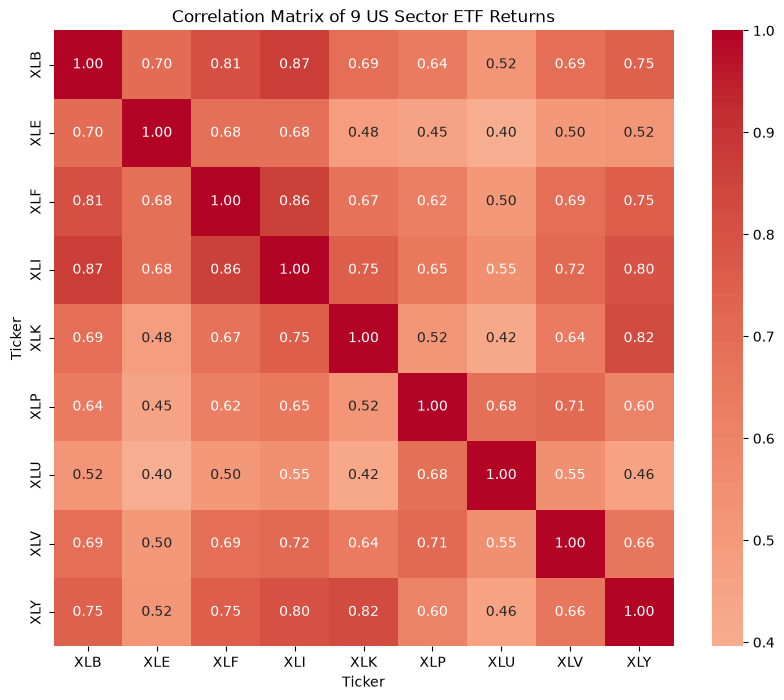

In [212]:
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center = 0
)

plt.title("Correlation Matrix of 9 US Sector ETF Returns")
plt.show()


In [213]:
rolling_vol_60 = (
    sector_returns.rolling(window=60).std() * np.sqrt(252)
)



In [214]:
rolling_vol_60.head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2010-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [215]:
rolling_vol_60.dropna().head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2010-03-31,0.234928,0.200846,0.210133,0.166290,0.166570,0.094664,0.137362,0.142246,0.141337
2010-04-01,0.237496,0.203458,0.207690,0.166528,0.166587,0.095346,0.138393,0.141040,0.141713
2010-04-05,0.236271,0.205231,0.208443,0.166915,0.166634,0.095302,0.138416,0.139773,0.143313
2010-04-06,0.235708,0.205209,0.205239,0.165881,0.166404,0.095664,0.139178,0.139636,0.142675
2010-04-07,0.234377,0.205743,0.204961,0.163868,0.166127,0.096453,0.140638,0.139934,0.143025


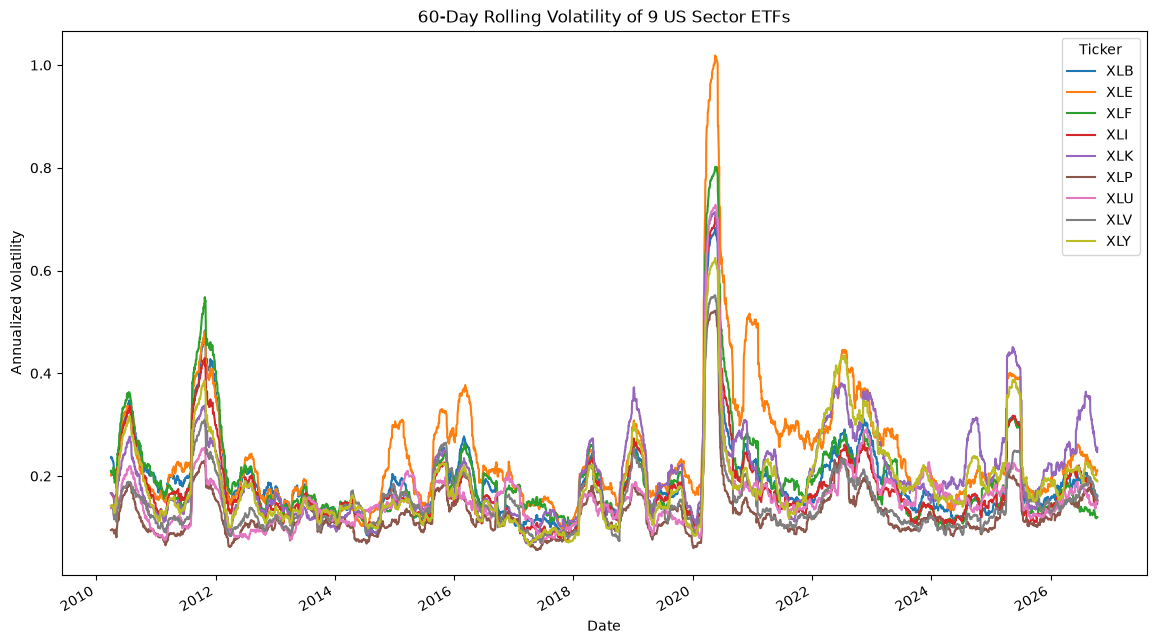

In [216]:
rolling_vol_60.plot(
    figsize=(14,8),
    title="60-Day Rolling Volatility of 9 US Sector ETFs"
)

plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.show()

In [217]:
rolling_corr_XLK_XLF = (
    sector_returns["XLK"].rolling(window=60).corr(sector_returns["XLF"])
)

In [218]:
rolling_corr_XLK_XLF.dropna().head()

Date
2010-03-31    0.722815
2010-04-01    0.732393
2010-04-05    0.742693
2010-04-06    0.766506
2010-04-07    0.776930
dtype: float64

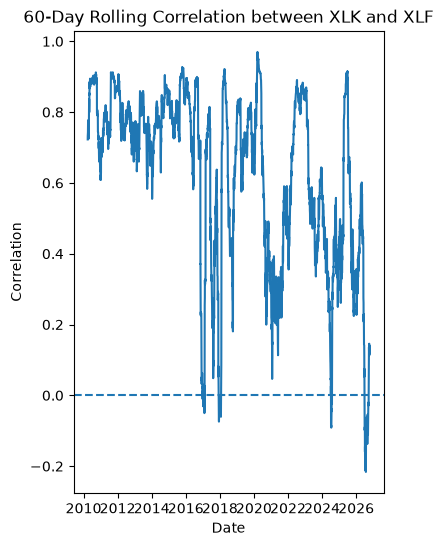

In [219]:
plt.figure(figsize=(4, 6))

plt.plot(
    rolling_corr_XLK_XLF.index,
    rolling_corr_XLK_XLF
)

plt.axhline(0, linestyle="--")

plt.title("60-Day Rolling Correlation between XLK and XLF")
plt.xlabel("Date")
plt.ylabel("Correlation")
plt.show()


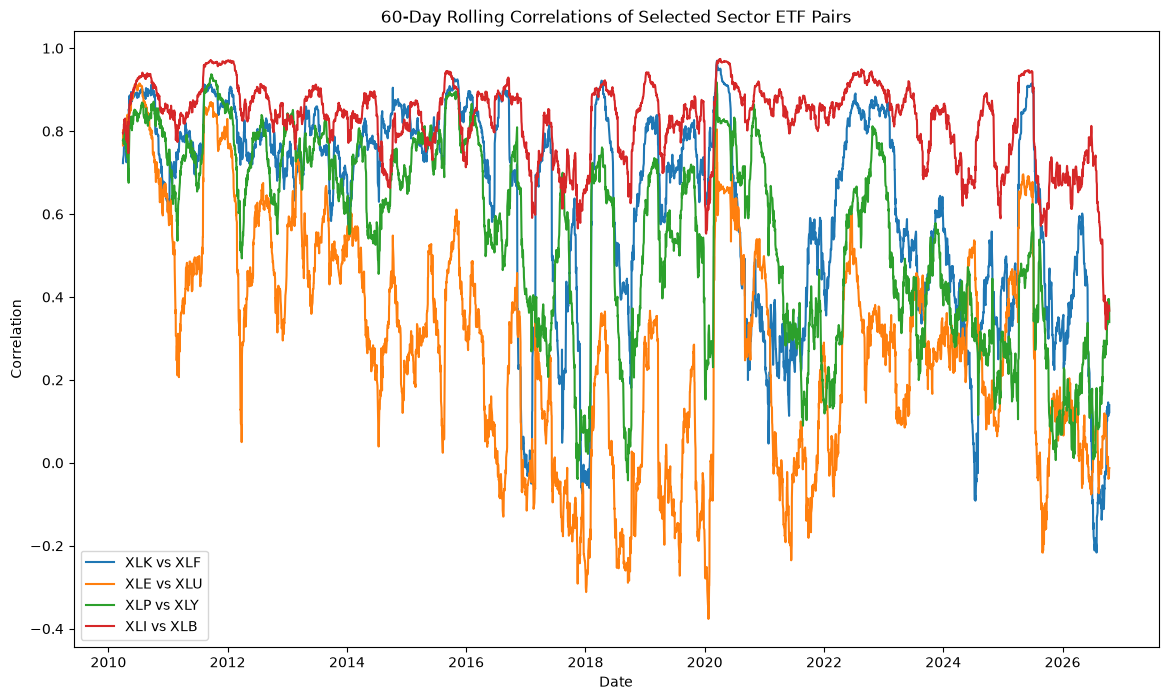

In [220]:
pairs = [
    ("XLK", "XLF"),
    ("XLE", "XLU"),
    ("XLP", "XLY"),
    ("XLI", "XLB")
     
]

plt.figure(figsize=(14, 8))

for etf1, etf2 in pairs:
    rolling_corr = (
        sector_returns[etf1].rolling(window=60).corr(sector_returns[etf2])
    )
    
    plt.plot(
        rolling_corr.index,
        rolling_corr,
        label=f"{etf1} vs {etf2}"
    )

plt.title("60-Day Rolling Correlations of Selected Sector ETF Pairs")
plt.xlabel("Date")
plt.ylabel("Correlation")
plt.legend()
plt.show()

In [221]:
spy_returns = returns["SPY"].copy()

In [222]:
spy_vol_60 = (
    spy_returns.rolling(window=60).std() * np.sqrt(252)
)

In [223]:
spy_vol_60.dropna().head()

Date
2010-03-31    0.141311
2010-04-01    0.141827
2010-04-05    0.142646
2010-04-06    0.142506
2010-04-07    0.143018
Name: SPY, dtype: float64

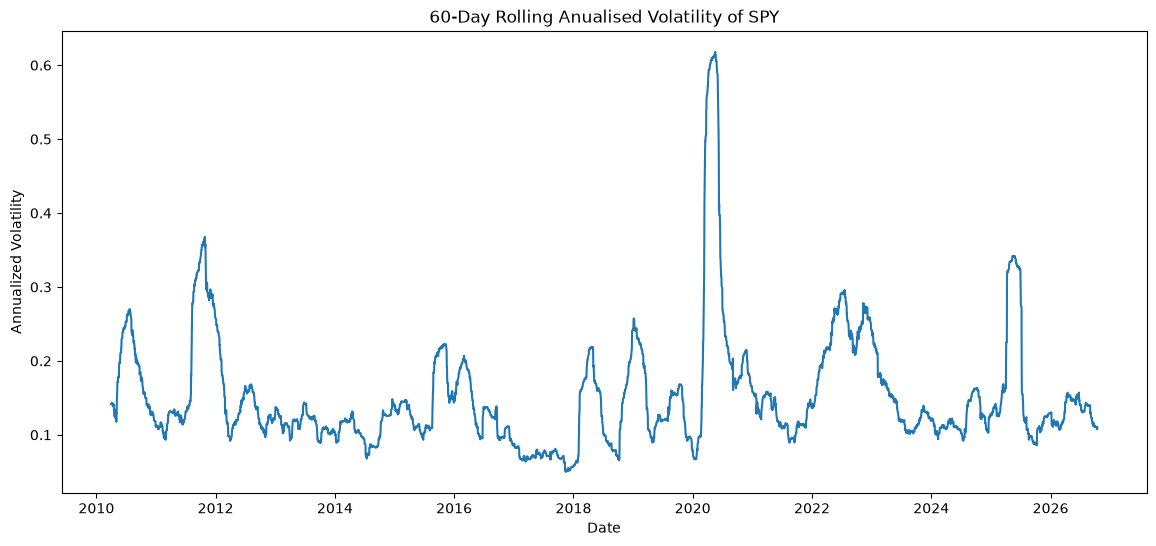

In [224]:
plt.figure(figsize=(14, 6))

plt.plot(
    spy_vol_60.index,
    spy_vol_60,
)

plt.title("60-Day Rolling Anualised Volatility of SPY")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.show()

In [225]:
sector_returns.to_csv(
    "sector_etf_daily_log_returns.csv"
)

In [226]:
summary_stats.to_csv(
    "sector_etf_summary_statistics.csv"
)

In [227]:
correlation_matrix.to_csv(
    "sector_etf_correlation_matrix.csv"
)

In [228]:
window = 60

historical_cov = (
    sector_returns.rolling(window=window).cov()
)

In [229]:
historical_cov.shape

(37962, 9)

In [230]:
historical_cov.tail(18)

Ticker                  XLB       XLE       XLF       XLI       XLK       XLP  \
Date       Ticker                                                               
2026-10-13 XLB     0.000105 -0.000012  0.000029  0.000037  0.000021  0.000041   
           XLE    -0.000012  0.000177 -0.000004 -0.000022 -0.000044 -0.000005   
           XLF     0.000029 -0.000004  0.000057  0.000034  0.000014  0.000028   
           XLI     0.000037 -0.000022  0.000034  0.000092  0.000077 -0.000002   
           XLK     0.000021 -0.000044  0.000014  0.000077  0.000241 -0.000064   
           XLP     0.000041 -0.000005  0.000028 -0.000002 -0.000064  0.000084   
           XLU     0.000017 -0.000002  0.000011  0.000032  0.000015  0.000013   
           XLV     0.000033 -0.000022  0.000019 -0.000006 -0.000046  0.000043   
           XLY     0.000044 -0.000037  0.000043  0.000029  0.000033  0.000042   
2026-10-14 XLB     0.000104 -0.000012  0.000029  0.000036  0.000021  0.000040   
           XLE    -0.000012  0.000177 -0.000004 -0.000022 -0.000047 -0.000004   
           XLF     0.000029 -0.000004  0.000057  0.000034  0.000017  0.000026   
           XLI     0.000036 -0.000022  0.000034  0.000093  0.000082 -0.000006   
           XLK     0.000021 -0.000047  0.000017  0.000082  0.000258 -0.000075   
           XLP     0.000040 -0.000004  0.000026 -0.000006 -0.000075  0.000092   
           XLU     0.000017 -0.000002  0.000011  0.000032  0.000016  0.000012   
           XLV     0.000030 -0.000020  0.000016 -0.000011 -0.000059  0.000051   
           XLY     0.000042 -0.000037  0.000043  0.000029  0.000037  0.000039   

Ticker                  XLU       XLV       XLY  
Date       Ticker                                
2026-10-13 XLB     0.000017  0.000033  0.000044  
           XLE    -0.000002 -0.000022 -0.000037  
           XLF     0.000011  0.000019  0.000043  
           XLI     0.000032 -0.000006  0.000029  
           XLK     0.000015 -0.000046  0.000033  
           XLP     0.000013  0.000043  0.000042  
           XLU     0.000089 -0.000002  0.000008  
           XLV    -0.000002  0.000097  0.000026  
           XLY     0.000008  0.000026  0.000142  
2026-10-14 XLB     0.000017  0.000030  0.000042  
           XLE    -0.000002 -0.000020 -0.000037  
           XLF     0.000011  0.000016  0.000043  
           XLI     0.000032 -0.000011  0.000029  
           XLK     0.000016 -0.000059  0.000037  
           XLP     0.000012  0.000051  0.000039  
           XLU     0.000089 -0.000004  0.000008  
           XLV    -0.000004  0.000103  0.000021  
           XLY     0.000008  0.000021  0.000143

In [231]:
last_date = sector_returns.index[-1]

cov_last = historical_cov.loc[last_date]

cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000104,-0.000012,0.000029,0.000036,0.000021,0.000040,0.000017,0.000030,0.000042
XLE,-0.000012,0.000177,-0.000004,-0.000022,-0.000047,-0.000004,-0.000002,-0.000020,-0.000037
XLF,0.000029,-0.000004,0.000057,0.000034,0.000017,0.000026,0.000011,0.000016,0.000043
XLI,0.000036,-0.000022,0.000034,0.000093,0.000082,-0.000006,0.000032,-0.000011,0.000029
XLK,0.000021,-0.000047,0.000017,0.000082,0.000258,-0.000075,0.000016,-0.000059,0.000037
XLP,0.000040,-0.000004,0.000026,-0.000006,-0.000075,0.000092,0.000012,0.000051,0.000039
XLU,0.000017,-0.000002,0.000011,0.000032,0.000016,0.000012,0.000089,-0.000004,0.000008
XLV,0.000030,-0.000020,0.000016,-0.000011,-0.000059,0.000051,-0.000004,0.000103,0.000021
XLY,0.000042,-0.000037,0.000043,0.000029,0.000037,0.000039,0.000008,0.000021,0.000143


In [232]:
cov_last.shape

(9, 9)

In [233]:
cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000104,-0.000012,0.000029,0.000036,0.000021,0.000040,0.000017,0.000030,0.000042
XLE,-0.000012,0.000177,-0.000004,-0.000022,-0.000047,-0.000004,-0.000002,-0.000020,-0.000037
XLF,0.000029,-0.000004,0.000057,0.000034,0.000017,0.000026,0.000011,0.000016,0.000043
XLI,0.000036,-0.000022,0.000034,0.000093,0.000082,-0.000006,0.000032,-0.000011,0.000029
XLK,0.000021,-0.000047,0.000017,0.000082,0.000258,-0.000075,0.000016,-0.000059,0.000037
XLP,0.000040,-0.000004,0.000026,-0.000006,-0.000075,0.000092,0.000012,0.000051,0.000039
XLU,0.000017,-0.000002,0.000011,0.000032,0.000016,0.000012,0.000089,-0.000004,0.000008
XLV,0.000030,-0.000020,0.000016,-0.000011,-0.000059,0.000051,-0.000004,0.000103,0.000021
XLY,0.000042,-0.000037,0.000043,0.000029,0.000037,0.000039,0.000008,0.000021,0.000143


In [234]:
np.allclose(cov_last.values, cov_last.values.T)

True

## EWMA covariance

Historical covariance gives every observation within the window effectively equal importance.

EWMA instead gives more recent observations greater weight.

So recent market behaviour influences the estimate more strongly.

In [235]:
lambda_ = 0.94

In [236]:
def ewma_covariance(returns_window, lambda_ =0.94):

    X = returns_window.values

    weights = np.array([
        (1 - lambda_) * lambda_ ** i
        for i in range(len(X))
    ])[::-1]  # Reverse the weights to align with the most recent observation

    weights = weights / weights.sum()  # Normalize the weights to sum to 1

    mean = np.average(
        X,
        axis=0,
        weights=weights
    ) 

    X_centered = X - mean

    cov = (
        X_centered.T @ (X_centered * weights[:, None])
    ) 

    return pd.DataFrame(
        cov,
        index=returns_window.columns,
        columns=returns_window.columns
    )   
                    

In [237]:
import pandas as pd
import numpy as np

latest_window = sector_returns.iloc[-60:]  # Get the last 60 rows of sector_returns

In [238]:
ewma_cov_last = ewma_covariance(
    latest_window,
    lambda_=0.94
)

ewma_cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000070,0.000022,0.000020,0.000037,0.000015,0.000033,0.000024,0.000008,0.000032
XLE,0.000022,0.000155,0.000021,0.000003,-0.000056,0.000032,0.000002,-0.000031,-0.000017
XLF,0.000020,0.000021,0.000053,0.000032,0.000010,0.000020,0.000021,0.000011,0.000033
XLI,0.000037,0.000003,0.000032,0.000075,0.000055,0.000005,0.000037,-0.000020,0.000038
XLK,0.000015,-0.000056,0.000010,0.000055,0.000182,-0.000081,0.000026,-0.000057,0.000047
XLP,0.000033,0.000032,0.000020,0.000005,-0.000081,0.000095,0.000016,0.000055,0.000013
XLU,0.000024,0.000002,0.000021,0.000037,0.000026,0.000016,0.000093,-0.000005,0.000038
XLV,0.000008,-0.000031,0.000011,-0.000020,-0.000057,0.000055,-0.000005,0.000110,0.000007
XLY,0.000032,-0.000017,0.000033,0.000038,0.000047,0.000013,0.000038,0.000007,0.000077


In [239]:
ewma_cov_last.shape

(9, 9)

In [240]:
np.allclose(
    ewma_cov_last.values,
    ewma_cov_last.values.T
)

True

In [241]:
cov_difference = ewma_cov_last - cov_last

cov_difference

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,-0.000033,0.000034,-0.000009,0.000001,-0.000006,-0.000007,7.015350e-06,-2.240095e-05,-0.000010
XLE,0.000034,-0.000022,0.000025,0.000025,-0.000010,0.000036,3.903275e-06,-1.051869e-05,0.000020
XLF,-0.000009,0.000025,-0.000004,-0.000002,-0.000007,-0.000006,9.388360e-06,-5.252698e-06,-0.000009
XLI,0.000001,0.000025,-0.000002,-0.000018,-0.000026,0.000011,4.697471e-06,-9.091404e-06,0.000009
XLK,-0.000006,-0.000010,-0.000007,-0.000026,-0.000076,-0.000006,9.973514e-06,1.607715e-06,0.000010
XLP,-0.000007,0.000036,-0.000006,0.000011,-0.000006,0.000004,3.967577e-06,4.073115e-06,-0.000026
XLU,0.000007,0.000004,0.000009,0.000005,0.000010,0.000004,4.212453e-06,-9.946243e-07,0.000030
XLV,-0.000022,-0.000011,-0.000005,-0.000009,0.000002,0.000004,-9.946243e-07,6.753490e-06,-0.000014
XLY,-0.000010,0.000020,-0.000009,0.000009,0.000010,-0.000026,3.022123e-05,-1.415050e-05,-0.000066


In [242]:
np.allclose(
    ewma_cov_last.values,
    cov_last.values
)

False

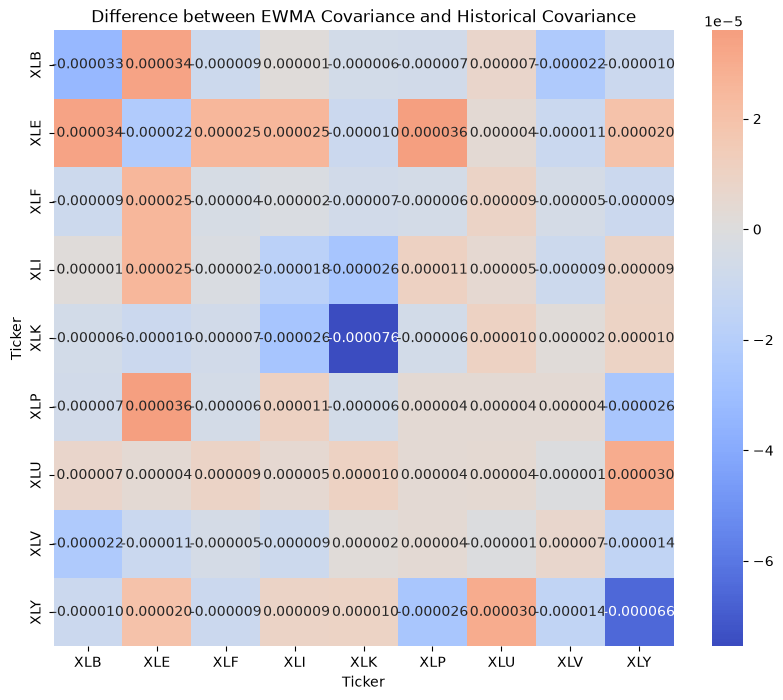

In [243]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

sns.heatmap(
    cov_difference,
    annot=True,
    fmt=" .6f",
    cbar=True,
    center=0,
    cmap="coolwarm"
)

plt.title("Difference between EWMA Covariance and Historical Covariance")

plt.show()

### EWMA vs Historical Covariance

The heatmap shows the difference between the EWMA and historical
covariance estimates for the latest observation window.

Positive values indicate that EWMA produces a higher covariance
estimate, while negative values indicate a lower estimate.

The differences confirm that EWMA responds differently from the
equally weighted historical estimator because it places greater
weight on recent observations. The largest diagonal difference is
observed for XLK, indicating a notable difference in the estimated
recent variance of the technology sector.

The difference matrix is symmetric, as expected for covariance
matrices.

In [244]:
historical_eigenvalues = np.linalg.eigvals(cov_last.values)

historical_eigenvalues

array([3.59756261e-04+0.j, 2.66848768e-04+0.j, 1.59655287e-04+0.j,
       9.89391916e-05+0.j, 7.83423293e-05+0.j, 2.15076016e-05+0.j,
       2.90707685e-05+0.j, 4.85621908e-05+0.j, 5.16820292e-05+0.j])

In [245]:
ewma_eigenvalues = np.linalg.eigvals(ewma_cov_last.values)

ewma_eigenvalues

array([3.07945499e-04+0.j, 2.22355241e-04+0.j, 1.73067757e-04+0.j,
       6.54031951e-05+0.j, 1.27957294e-05+0.j, 1.59345996e-05+0.j,
       4.57979002e-05+0.j, 3.62605560e-05+0.j, 3.13875463e-05+0.j])

In [246]:
print(
    "Historical minimum eigenvalues:",
    historical_eigenvalues.min()
    
)

print(
    "EWMA minimum eigenvalues:",
    ewma_eigenvalues.min()
)

Historical minimum eigenvalues: (2.1507601557101057e-05+0j)
EWMA minimum eigenvalues: (1.2795729415787462e-05+0j)


In [247]:
tolerance = 1e-10

print(
    "Historical PSD:",
    historical_eigenvalues.min() >= -tolerance
)

print(
    "EWMA PSD:",
    ewma_eigenvalues.min() >= -tolerance
)

Historical PSD: True
EWMA PSD: True


In [248]:
sector_returns.head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2010-01-05,0.003228,0.008129,0.018213,0.003525,-0.001290,0.000375,-0.011976,-0.009855,0.003661
2010-01-06,0.016851,0.011904,0.002003,0.002109,-0.011251,-0.000750,0.005844,0.010172,0.001327
2010-01-07,-0.007809,-0.001501,0.021123,0.010826,-0.003924,0.000000,-0.004543,0.003473,0.008258
2010-01-08,0.013841,0.006488,-0.005896,0.015851,0.006531,-0.003382,-0.000976,0.001574,-0.000329
2010-01-11,-0.005456,-0.001328,0.000656,0.010881,-0.003913,0.002631,0.010363,0.005648,-0.001977


In [249]:
sector_returns.shape

(4218, 9)

In [250]:
sector_returns.columns

Index(['XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY'], dtype='str', name='Ticker')

In [251]:
window = 60

In [252]:
historical_cov = (
    sector_returns
    .rolling(window=window)
    .cov()
)

In [253]:
historical_cov.head()

Ticker             XLB  XLE  XLF  XLI  XLK  XLP  XLU  XLV  XLY
Date       Ticker                                             
2010-01-05 XLB     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
           XLE     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
           XLF     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
           XLI     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
           XLK     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN

In [254]:
historical_cov.shape

(37962, 9)

In [255]:
last_date = sector_returns.index[-1]

print(last_date)

2026-10-14 00:00:00


In [256]:
cov_last = historical_cov.loc[last_date]

cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000104,-0.000012,0.000029,0.000036,0.000021,0.000040,0.000017,0.000030,0.000042
XLE,-0.000012,0.000177,-0.000004,-0.000022,-0.000047,-0.000004,-0.000002,-0.000020,-0.000037
XLF,0.000029,-0.000004,0.000057,0.000034,0.000017,0.000026,0.000011,0.000016,0.000043
XLI,0.000036,-0.000022,0.000034,0.000093,0.000082,-0.000006,0.000032,-0.000011,0.000029
XLK,0.000021,-0.000047,0.000017,0.000082,0.000258,-0.000075,0.000016,-0.000059,0.000037
XLP,0.000040,-0.000004,0.000026,-0.000006,-0.000075,0.000092,0.000012,0.000051,0.000039
XLU,0.000017,-0.000002,0.000011,0.000032,0.000016,0.000012,0.000089,-0.000004,0.000008
XLV,0.000030,-0.000020,0.000016,-0.000011,-0.000059,0.000051,-0.000004,0.000103,0.000021
XLY,0.000042,-0.000037,0.000043,0.000029,0.000037,0.000039,0.000008,0.000021,0.000143


In [257]:
cov_last.shape

(9, 9)

In [258]:
cov_last.loc["XLK", "XLK"]

np.float64(0.00025794957152645864)

In [259]:
np.allclose(
    cov_last.values,
    cov_last.values.T
)

True

In [260]:
print(cov_last.loc["XLK", "XLF"])
print(cov_last.loc["XLF", "XLK"])

1.68102360497351e-05
1.68102360497351e-05


In [261]:
pd.Series(
    np.diag(cov_last),
    index = cov_last.columns,
    name = "Variance"
)

Ticker
XLB    0.000104
XLE    0.000177
XLF    0.000057
XLI    0.000093
XLK    0.000258
XLP    0.000092
XLU    0.000089
XLV    0.000103
XLY    0.000143
Name: Variance, dtype: float64

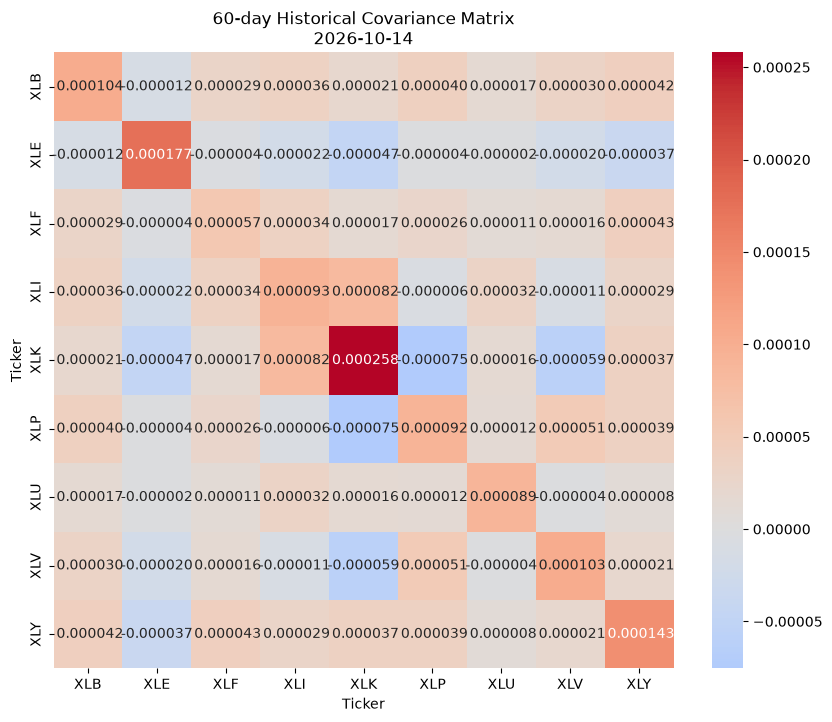

In [262]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize = (10, 8))

sns.heatmap(
    cov_last,
    annot=True,
    fmt=" .6f",
    cmap="coolwarm",
    center=0
)

plt.title(
    f"60-day Historical Covariance Matrix\n{last_date.date()}"
)

plt.show()

In [263]:
first_valid_date = (
    historical_cov
    .dropna()
    .index
    .get_level_values(0)[0]
)

print("First valid covariance date:", first_valid_date)

First valid covariance date: 2010-03-31 00:00:00


In [264]:
latest_60_returns = sector_returns.iloc[-60:]

In [265]:
manual_cov = latest_60_returns.cov()

In [266]:
np.allclose(
    manual_cov.values,
    cov_last.values
)

True

### Historical Covariance Baseline

A rolling sample covariance estimator was implemented using a
60-trading-day lookback window. At each date, the covariance matrix
is estimated using only the observations contained within the
historical window.

The estimator produces a 9 × 9 covariance matrix corresponding to
the nine US sector ETFs.

The 60-day window is initially used for baseline implementation and
will be treated as an experimental design choice rather than assumed
to be universally optimal.

The historical covariance estimator provides a transparent empirical
baseline against which more adaptive and regularised covariance
estimators can be evaluated.

In [267]:
lambda_ = 0.94

In [268]:
latest_window = sector_returns.iloc[-window:]

latest_window.shape

(60, 9)

In [269]:
latest_window.head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2026-07-21,0.001398,0.009619,0.001248,0.003027,0.028446,-0.009472,-0.000445,0.006260,0.002266
2026-07-22,0.014269,0.011895,-0.001070,0.001063,-0.002825,0.003800,0.022235,-0.005130,-0.007427
2026-07-23,-0.010484,0.003036,-0.003933,0.017130,-0.010147,-0.013963,0.005645,0.012529,-0.047230
2026-07-24,0.019104,0.004034,0.008561,0.003950,-0.014506,0.010996,0.002163,0.006975,0.005959
2026-07-27,0.002533,-0.021360,0.010072,0.002952,-0.009024,0.014514,-0.013265,0.005092,0.012985


In [270]:
latest_window.tail()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2026-10-08,0.005903,0.029240,0.008891,0.003331,-0.018088,0.020834,-0.001946,-0.003858,0.003138
2026-10-09,0.003242,-0.002455,0.009178,0.005035,0.005043,0.000120,0.008244,0.015636,0.010153
2026-10-12,0.000202,0.014189,0.005830,-0.000591,-0.012249,0.011678,0.005299,0.006885,-0.005153
2026-10-13,0.005648,0.017867,-0.004187,-0.002842,-0.000408,-0.002610,0.005748,-0.013640,0.000801
2026-10-14,-0.001006,0.006378,-0.005487,-0.009711,-0.030258,0.021969,-0.003589,0.025029,-0.007683


In [271]:
def ewma_covariance(returns_window, lambda_ =0.94):
    X = returns_window.values

    n = len(X)

    weights = np.array([
        (1 - lambda_) * lambda_ ** i
        for i in range(n)
    ])[::-1]

    weights = weights / weights.sum()

    mean = np.average(
        X,
        axis=0,
        weights=weights
    )

    X_centered = X - mean

    cov = (
        X_centered.T
        @ (X_centered * weights[:, None])
    )

    return pd.DataFrame(
        cov,
        index=returns_window.columns,
        columns=returns_window.columns
    )

In [272]:
lambda_ = 0.94
n = window

weights = np.array([
    (1 - lambda_) * lambda_ ** i
    for i in range(n)
])[::-1]

weights = weights / weights.sum()

In [273]:
weights[:5]

array([0.00159746, 0.00169943, 0.0018079 , 0.0019233 , 0.00204606])

In [274]:
weights[-5:]

array([0.04801732, 0.05108225, 0.05434282, 0.05781152, 0.06150161])

In [275]:
weights.sum()

np.float64(1.0)

<function matplotlib.pyplot.show(close=None, block=None)>

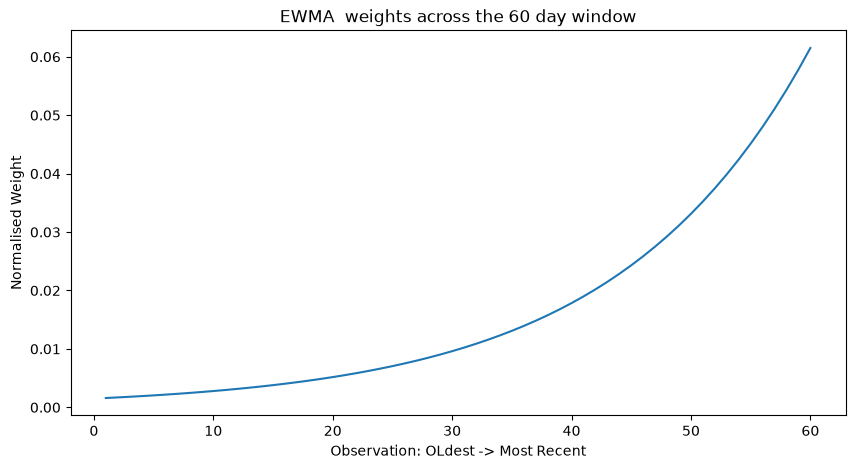

In [276]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, window + 1),
    weights
)

plt.title("EWMA  weights across the 60 day window")
plt.xlabel("Observation: OLdest -> Most Recent")
plt.ylabel("Normalised Weight")

plt.show

In [277]:
ewma_cov_last = ewma_covariance(
    latest_window,
    lambda_=0.94
)

ewma_cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000070,0.000022,0.000020,0.000037,0.000015,0.000033,0.000024,0.000008,0.000032
XLE,0.000022,0.000155,0.000021,0.000003,-0.000056,0.000032,0.000002,-0.000031,-0.000017
XLF,0.000020,0.000021,0.000053,0.000032,0.000010,0.000020,0.000021,0.000011,0.000033
XLI,0.000037,0.000003,0.000032,0.000075,0.000055,0.000005,0.000037,-0.000020,0.000038
XLK,0.000015,-0.000056,0.000010,0.000055,0.000182,-0.000081,0.000026,-0.000057,0.000047
XLP,0.000033,0.000032,0.000020,0.000005,-0.000081,0.000095,0.000016,0.000055,0.000013
XLU,0.000024,0.000002,0.000021,0.000037,0.000026,0.000016,0.000093,-0.000005,0.000038
XLV,0.000008,-0.000031,0.000011,-0.000020,-0.000057,0.000055,-0.000005,0.000110,0.000007
XLY,0.000032,-0.000017,0.000033,0.000038,0.000047,0.000013,0.000038,0.000007,0.000077


In [278]:
ewma_cov_last.shape

(9, 9)

In [279]:
np.allclose(
    ewma_cov_last.values,
    ewma_cov_last.values.T
)

True

In [280]:
print(ewma_cov_last.loc["XLK", "XLF"])
print(ewma_cov_last.loc["XLF", "XLK"])

9.836215148422195e-06
9.836215148422197e-06


In [281]:
pd.Series(
    np.diag(ewma_cov_last),
    index=ewma_cov_last.columns,
    name="EWMA Variance"
)

Ticker
XLB    0.000070
XLE    0.000155
XLF    0.000053
XLI    0.000075
XLK    0.000182
XLP    0.000095
XLU    0.000093
XLV    0.000110
XLY    0.000077
Name: EWMA Variance, dtype: float64

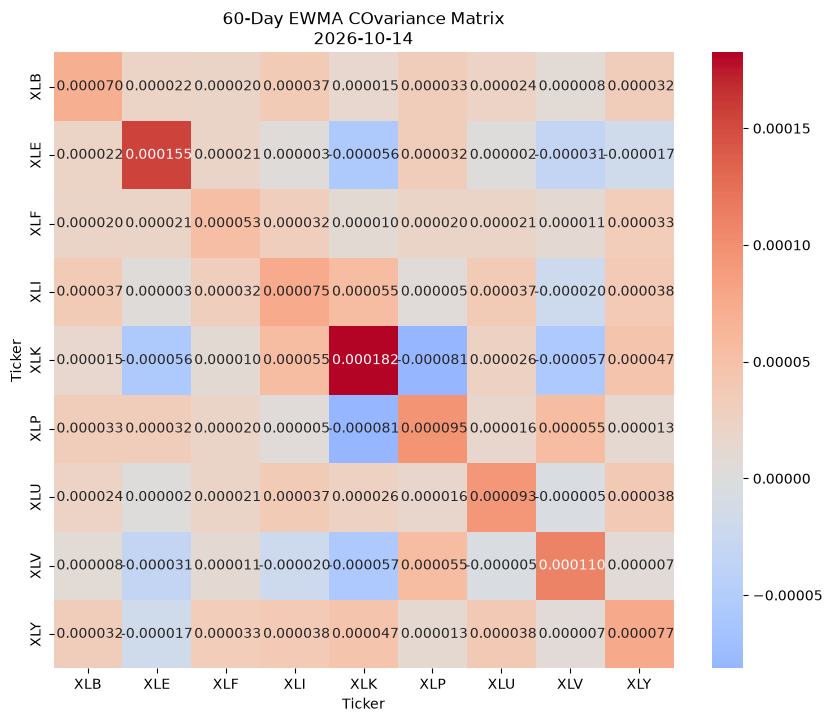

In [282]:
plt.figure(figsize=(10,8))

sns.heatmap(
    ewma_cov_last,
    annot=True,
    fmt=" .6f",
    cmap="coolwarm",
    center=0
)

plt.title(
    f"60-Day EWMA COvariance Matrix\n{last_date.date()}"
)

plt.show()

In [283]:
print(
    "Historical XLK-XLF:",
    cov_last.loc["XLK", "XLF"]
)

print(
    "EWMA XLK-XLF:",
    ewma_cov_last.loc["XLK", "XLF"]
)

Historical XLK-XLF: 1.68102360497351e-05
EWMA XLK-XLF: 9.836215148422195e-06


### EWMA Covariance Baseline

An Exponentially Weighted Moving Average (EWMA) covariance estimator
was implemented as a time-responsive baseline.

The estimator uses the same 60-trading-day information window as the
historical covariance baseline but assigns greater weight to more
recent observations through exponential decay.

An initial decay factor of λ = 0.94 is used for baseline
implementation. This value is treated as an experimental parameter
rather than assumed to be universally optimal.

EWMA provides a useful comparator because it introduces predetermined
temporal adaptation without learning estimator-selection or
combination behaviour from market-state variables.

In [284]:

print("Historical shape:", cov_last.shape)
print("EWMA shape:", ewma_cov_last.shape)

print(
    "Same assets:",
    list(cov_last.columns) == list(ewma_cov_last.columns)
)

Historical shape: (9, 9)
EWMA shape: (9, 9)
Same assets: True


In [285]:
cov_difference = ewma_cov_last - cov_last

cov_difference

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,-0.000033,0.000034,-0.000009,0.000001,-0.000006,-0.000007,7.015350e-06,-2.240095e-05,-0.000010
XLE,0.000034,-0.000022,0.000025,0.000025,-0.000010,0.000036,3.903275e-06,-1.051869e-05,0.000020
XLF,-0.000009,0.000025,-0.000004,-0.000002,-0.000007,-0.000006,9.388360e-06,-5.252698e-06,-0.000009
XLI,0.000001,0.000025,-0.000002,-0.000018,-0.000026,0.000011,4.697471e-06,-9.091404e-06,0.000009
XLK,-0.000006,-0.000010,-0.000007,-0.000026,-0.000076,-0.000006,9.973514e-06,1.607715e-06,0.000010
XLP,-0.000007,0.000036,-0.000006,0.000011,-0.000006,0.000004,3.967577e-06,4.073115e-06,-0.000026
XLU,0.000007,0.000004,0.000009,0.000005,0.000010,0.000004,4.212453e-06,-9.946243e-07,0.000030
XLV,-0.000022,-0.000011,-0.000005,-0.000009,0.000002,0.000004,-9.946243e-07,6.753490e-06,-0.000014
XLY,-0.000010,0.000020,-0.000009,0.000009,0.000010,-0.000026,3.022123e-05,-1.415050e-05,-0.000066


In [286]:
cov_difference.loc["XLK", "XLF"]

np.float64(-6.974020901312905e-06)

In [287]:
np.allclose(
    ewma_cov_last.values,
    cov_last.values
)

False

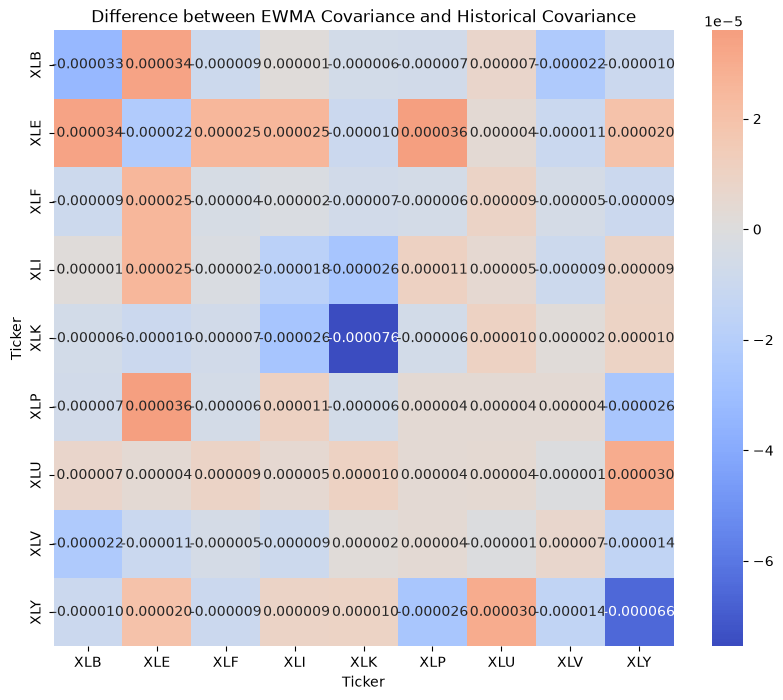

In [288]:
plt.figure(figsize=(10,8))

sns.heatmap(
    cov_difference,
    annot=True,
    fmt=" .6f",
    cmap="coolwarm",
    center=0
)

plt.title("Difference between EWMA Covariance and Historical Covariance")

plt.show()

In [289]:
variance_comparison = pd.DataFrame({
    "Historical": np.diag(cov_last),
    "EWMA": np.diag(ewma_cov_last)
}, index=cov_last.columns)

variance_comparison["Difference"] = (
    variance_comparison["EWMA"] - variance_comparison["Historical"]
)

variance_comparison

,Historical,EWMA,Difference
Ticker,,,
XLB,0.000104,0.000070,-0.000033
XLE,0.000177,0.000155,-0.000022
XLF,0.000057,0.000053,-0.000004
XLI,0.000093,0.000075,-0.000018
XLK,0.000258,0.000182,-0.000076
XLP,0.000092,0.000095,0.000004
XLU,0.000089,0.000093,0.000004
XLV,0.000103,0.000110,0.000007
XLY,0.000143,0.000077,-0.000066


In [290]:
frobenius_difference = np.linalg.norm(
    ewma_cov_last.values - cov_last.values,
    ord="fro"
)

print(
    "Frobenius distance between Historical and EWMA:",
    frobenius_difference)

Frobenius distance between Historical and EWMA: 0.0001703391308600493


### Historical vs EWMA Covariance

The Historical and EWMA estimators produce different covariance
estimates despite being calculated from the same 60-day information
window.

The Historical estimator treats observations approximately equally,
whereas EWMA assigns greater importance to recent observations.
Consequently, differences are observed in both individual asset
variances and cross-asset covariances.

These differences do not establish that either estimator is superior.
Their relative usefulness must be evaluated out of sample, particularly
through their downstream effect on portfolio risk and stability.

In [291]:
historical_eigenvalues = np.linalg.eigvalsh(
    cov_last.values
)

historical_eigenvalues

array([2.15076016e-05, 2.90707685e-05, 4.85621908e-05, 5.16820292e-05,
       7.83423293e-05, 9.89391916e-05, 1.59655287e-04, 2.66848768e-04,
       3.59756261e-04])

In [292]:
print(
    "Historical minimum eigenvalue:",
    historical_eigenvalues.min()
)

Historical minimum eigenvalue: 2.15076015571011e-05


In [293]:
ewma_eigenvalues = np.linalg.eigvalsh(
    ewma_cov_last.values
)

ewma_eigenvalues

array([1.27957294e-05, 1.59345996e-05, 3.13875463e-05, 3.62605560e-05,
       4.57979002e-05, 6.54031951e-05, 1.73067757e-04, 2.22355241e-04,
       3.07945499e-04])

In [294]:
print(
    "EWMA minimum eigenvalue:",
    ewma_eigenvalues.min()
)

EWMA minimum eigenvalue: 1.279572941578748e-05


In [295]:
tolerance = 1e-10

historical_psd = (
    historical_eigenvalues.min() >= -tolerance
)

ewma_psd = (
    ewma_eigenvalues.min() >= -tolerance
)

print("Historical PSD:", historical_psd)
print("EWMA PSD:", ewma_psd)

Historical PSD: True
EWMA PSD: True


In [296]:
eigenvalue_comparison = pd.DataFrame({
    "HIstorical": historical_eigenvalues,
    "EWMA": ewma_eigenvalues
})

eigenvalue_comparison.index = [
    f"Eigenvalue {i+1}"
    for i in range(len(eigenvalue_comparison))
]

eigenvalue_comparison

,HIstorical,EWMA
Eigenvalue 1,0.000022,0.000013
Eigenvalue 2,0.000029,0.000016
Eigenvalue 3,0.000049,0.000031
Eigenvalue 4,0.000052,0.000036
Eigenvalue 5,0.000078,0.000046
Eigenvalue 6,0.000099,0.000065
Eigenvalue 7,0.000160,0.000173
Eigenvalue 8,0.000267,0.000222
Eigenvalue 9,0.000360,0.000308


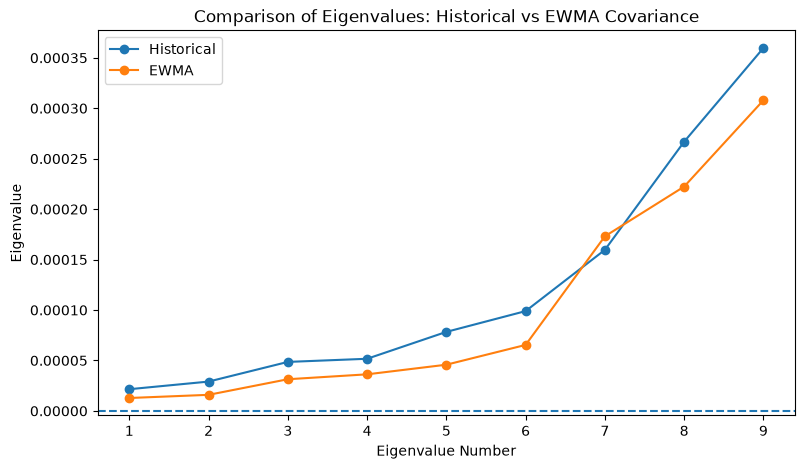

In [297]:
plt.figure(figsize=(9,5))

plt.plot(
    range(1, 10),
    historical_eigenvalues,
    marker="o",
    label="Historical"
)

plt.plot(
    range(1, 10),
    ewma_eigenvalues,
    marker="o",
    label="EWMA"
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Eigenvalue Number")
plt.ylabel("Eigenvalue")
plt.title("Comparison of Eigenvalues: Historical vs EWMA Covariance")
plt.legend()

plt.show()

In [298]:
print(
    "HIstorical postivie definite:",
    historical_eigenvalues.min() >= tolerance
)

print(
    "EWMA postivie definite:",
    ewma_eigenvalues.min() >= tolerance
)

HIstorical postivie definite: True
EWMA postivie definite: True


In [299]:
historical_condition = np.linalg.cond(
    cov_last.values
)

wema_condition = np.linalg.cond(
    ewma_cov_last.values
)

print(
    "Historical condition number:",
    historical_condition
)

print(
    "EWMA condition number:",
    wema_condition
)


Historical condition number: 16.726935372446636
EWMA condition number: 24.06627159854555


### Covariance Validity and Eigenvalue Diagnostics

The Historical and EWMA covariance estimates were assessed for
positive semi-definiteness (PSD), an important mathematical property
of covariance matrices.

For a symmetric covariance matrix, PSD can be evaluated by examining
its eigenvalues. A matrix is PSD when its eigenvalues are
non-negative, subject to a small numerical tolerance for floating-point
error.

The minimum eigenvalue of each covariance estimate was therefore
examined alongside its overall eigenvalue spectrum. Condition numbers
were also calculated as an initial diagnostic of numerical
conditioning.

These checks establish mathematical and numerical diagnostics for the
baseline estimators before they are incorporated into downstream
portfolio optimisation.

In [300]:
from sklearn.covariance import LedoitWolf

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [301]:
window = 60

latest_window = sector_returns.iloc[-window:].copy()

print("Window shape:", latest_window.shape)
print("Start date:", latest_window.index[0])
print("End date:", latest_window.index[-1])

Window shape: (60, 9)
Start date: 2026-07-21 00:00:00
End date: 2026-10-14 00:00:00


In [302]:
lw_model = LedoitWolf(
    assume_centered=False,
)

lw_model.fit(latest_window.values)

,"store_precision store_precision: bool, default=TrueSpecify if the estimated precision is stored.",True
,"assume_centered assume_centered: bool, default=FalseIf True, data will not be centered before computation.Useful when working with data whose mean is almost, but not exactlyzero.If False (default), data will be centered before computation.",False
,"block_size block_size: int, default=1000Size of blocks into which the covariance matrix will be splitduring its Ledoit-Wolf estimation. This is purely a memoryoptimization and does not affect results.",1000
Name,Type,Value
"covariance_ covariance_: ndarray of shape (n_features, n_features)Estimated covariance matrix.","ndarray[float64](9, 9)","[[ 0.,-0., 0.,..., 0., 0., 0.], [-0., 0.,-0.,...,-0.,-0.,-0.], [ 0.,-0., 0.,..., 0., 0., 0.], ..., [ 0.,-0., 0.,..., 0.,-0., 0.], [ 0.,-0., 0.,...,-0., 0., 0.], [ 0.,-0., 0.,..., 0., 0., 0.]]"
"location_ location_: ndarray of shape (n_features,)Estimated location, i.e. the estimated mean.","ndarray[float64](9,)","[ 0., 0.,-0.,...,-0., 0.,-0.]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
"precision_ precision_: ndarray of shape (n_features, n_features)Estimated pseudo inverse matrix.(stored only if store_precision is True)","ndarray[float64](9, 9)","[[11943.98, -278.48, -871.92,..., -436.05,-1885.45,-1113.78], [ -278.48, 6803. , -846.84,..., -172.99, 1396.1 , 1085.97], [ -871.92, -846.84,17695.15,..., -62.56,-1181.74,-2794.28], ..., [ -436.05, -172.99, -62.56,...,11316.49, 579.25, 273.58], [-1885.45, 1396.1 ,-1181.74,..., 579.25,12020.08, -371.31], [-1113.78, 1085.97,-2794.28,..., 273.58, -371.31, 9428.24]]"
"shrinkage_ shrinkage_: floatCoefficient in the convex combination used for the computationof the shrunk estimate. Range is [0, 1].",float64,0.2404


In [303]:
shrinkage_cov_last = pd.DataFrame(
    lw_model.covariance_,
    index=latest_window.columns,
    columns=latest_window.columns
)

shrinkage_cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000107,-0.000009,0.000022,0.000027,0.000016,0.000030,0.000012,0.000023,0.000032
XLE,-0.000009,0.000161,-0.000003,-0.000016,-0.000035,-0.000003,-0.000001,-0.000015,-0.000028
XLF,0.000022,-0.000003,0.000072,0.000025,0.000013,0.000019,0.000008,0.000012,0.000032
XLI,0.000027,-0.000016,0.000025,0.000098,0.000061,-0.000005,0.000024,-0.000008,0.000022
XLK,0.000016,-0.000035,0.000013,0.000061,0.000222,-0.000056,0.000012,-0.000044,0.000028
XLP,0.000030,-0.000003,0.000019,-0.000005,-0.000056,0.000098,0.000009,0.000038,0.000029
XLU,0.000012,-0.000001,0.000008,0.000024,0.000012,0.000009,0.000096,-0.000003,0.000006
XLV,0.000023,-0.000015,0.000012,-0.000008,-0.000044,0.000038,-0.000003,0.000106,0.000016
XLY,0.000032,-0.000028,0.000032,0.000022,0.000028,0.000029,0.000006,0.000016,0.000136


In [304]:
shrinkage_cov_last.shape

(9, 9)

In [305]:
shrinkage_intensity = lw_model.shrinkage_

print("Shrinkage intensity:", shrinkage_intensity)

Shrinkage intensity: 0.24040431441548027


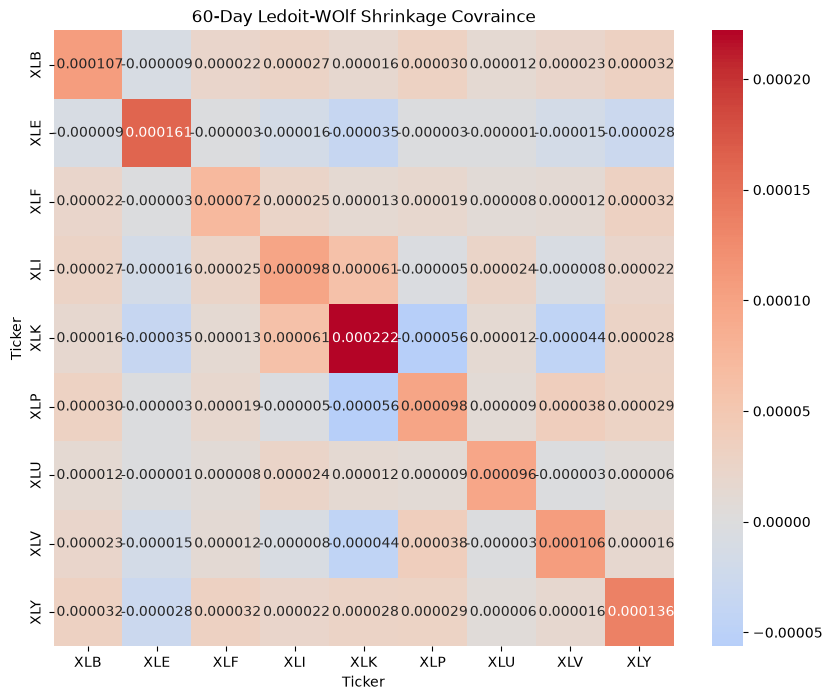

In [306]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    shrinkage_cov_last,
    annot=True,
    fmt=" .6f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "60-Day Ledoit-WOlf Shrinkage Covraince"
)

plt.show()

In [307]:
variance_comparison_3 = pd.DataFrame({
    "Historical": np.diag(cov_last.values),
    "EWMA": np.diag(ewma_cov_last.values),
    "Ledoit-Wolf": np.diag(shrinkage_cov_last.values)
}, index=sector_returns.columns)

variance_comparison_3

,Historical,EWMA,Ledoit-Wolf
Ticker,,,
XLB,0.000104,0.000070,0.000107
XLE,0.000177,0.000155,0.000161
XLF,0.000057,0.000053,0.000072
XLI,0.000093,0.000075,0.000098
XLK,0.000258,0.000182,0.000222
XLP,0.000092,0.000095,0.000098
XLU,0.000089,0.000093,0.000096
XLV,0.000103,0.000110,0.000106
XLY,0.000143,0.000077,0.000136


In [308]:
print(
    "HIstorical vs EWMA:",
    np.linalg.norm(
        cov_last.values - ewma_cov_last.values,
        ord="fro"
    )
)

print(
    "HIstorical vs Shrinkage:",
    np.linalg.norm(
        cov_last.values - shrinkage_cov_last.values,
        ord="fro"
    )
)

print(
    "EWMA vs Shrinkage:",
    np.linalg.norm(
        ewma_cov_last.values - shrinkage_cov_last.values,
        ord="fro"
    )
)

HIstorical vs EWMA: 0.0001703391308600493
HIstorical vs Shrinkage: 8.431481349886459e-05
EWMA vs Shrinkage: 0.0001556380681606628


In [309]:
shrinkage_eigenvalues = np.linalg.eigvalsh(
    shrinkage_cov_last.values
)

print(
    "Minimum eigenvalue:",
    shrinkage_eigenvalues.min()
)

print(
    "Shrinkage PSD:",
    shrinkage_eigenvalues.min() >= -1e-10
)

Minimum eigenvalue: 4.533513545434786e-05
Shrinkage PSD: True


In [310]:
condition_comparison = pd.Series({
    "HIstorical": np.linalg.cond(cov_last.values),
    "EWMA": np.linalg.cond(ewma_cov_last.values),
    "Ledoit-Wolf": np.linalg.cond(shrinkage_cov_last.values)
})

condition_comparison

HIstorical     16.726935
EWMA           24.066272
Ledoit-Wolf     6.572941
dtype: float64

In [311]:
X = latest_window.values

# Maximum-likelihood sample covariance
S = np.cov(
    X,
    rowvar=False,
    bias=True
)

#Scaled identity target
mu = np.trace(S) / S.shape[0]

T = mu * np.eye(S.shape[0])

alpha = lw_model.shrinkage_

manual_shrinkage = (
    (1 - alpha) * S + alpha * T
)

print(
    "Manual formula matches sklearn:",
    np.allclose(
        manual_shrinkage,
        shrinkage_cov_last.values
    )
)

Manual formula matches sklearn: True


### Ledoit–Wolf Shrinkage Covariance Baseline

A Ledoit–Wolf linear shrinkage covariance estimator was implemented
as a regularised covariance-estimation baseline.

The estimator combines the sample covariance matrix with a scaled
identity target, using a data-driven shrinkage intensity.

A 60-trading-day estimation window was initially used to maintain
a comparable information window across the Historical, EWMA and
Ledoit–Wolf estimators.

The resulting 9 × 9 covariance matrix was assessed for symmetry,
positive semi-definiteness and numerical conditioning.

The shrinkage estimator represents a distinct regularisation-based
approach and provides an additional candidate covariance expert for
the proposed AdaptiveCov-X framework.

The final lookback-window and estimator settings will be determined
through the experimental design and validation process.

In [312]:
import numpy as np
import pandas as pd

from scipy.optimize import minimize

In [313]:
def portfolio_variance(weights, covariance_matrix):
    return weights.T @ covariance_matrix @ weights

In [314]:
def minimum_variance_portfolio(covariance_matrix):

    Sigma = np.asarray(
        covariance_matrix,
        dtype=float
    )

    n_assets = Sigma.shape[0]

    initial_weights = np.ones(n_assets) / n_assets

    constraints = ({
        "type": "eq",
        "fun": lambda w: np.sum(w) - 1
    })

    bounds = [
        (0.0, 1.0)
        for _ in range(n_assets)
    ]

    result = minimize(
        fun=portfolio_variance,
        x0=initial_weights,
        args=(Sigma,),
        method = "SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={
            "ftol": 1e-12,
            "maxiter": 1000
        }
    )

    if not result.success:
        raise RuntimeError(
            f"Optimization failed: {result.message}"
        )

    return result.x


In [315]:
weights_historical = minimum_variance_portfolio(
    cov_last
)

print(weights_historical)

[0.         0.18139557 0.06974661 0.04120026 0.17794232 0.19291535
 0.12614607 0.20782662 0.0028272 ]


In [316]:
print("Number of weights:", len(weights_historical))
print("Sum:", weights_historical.sum())
print("Minimum:", weights_historical.min())

Number of weights: 9
Sum: 1.0
Minimum: 0.0


In [317]:
weights_ewma = minimum_variance_portfolio(
    ewma_cov_last
)

print(weights_ewma)

[0.00000000e+00 2.17789226e-01 7.75766436e-18 5.09042562e-03
 2.96142088e-01 1.69480842e-01 4.70127456e-02 2.64484673e-01
 4.62592927e-18]


In [318]:
weights_shrinkage = minimum_variance_portfolio(
    shrinkage_cov_last
)

print(weights_shrinkage)

[0.01147768 0.17682797 0.0933367  0.0734293  0.14276404 0.1507031
 0.12628602 0.18453386 0.04064133]


In [319]:
portfolio_weights = pd.DataFrame({
    "HIstorical": weights_historical,
    "EWMA": weights_ewma,
    "Ledoit-Wolf": weights_shrinkage
}, index=sector_returns.columns)

portfolio_weights

,HIstorical,EWMA,Ledoit-Wolf
Ticker,,,
XLB,0.000000,0.000000e+00,0.011478
XLE,0.181396,2.177892e-01,0.176828
XLF,0.069747,7.757664e-18,0.093337
XLI,0.041200,5.090426e-03,0.073429
XLK,0.177942,2.961421e-01,0.142764
XLP,0.192915,1.694808e-01,0.150703
XLU,0.126146,4.701275e-02,0.126286
XLV,0.207827,2.644847e-01,0.184534
XLY,0.002827,4.625929e-18,0.040641


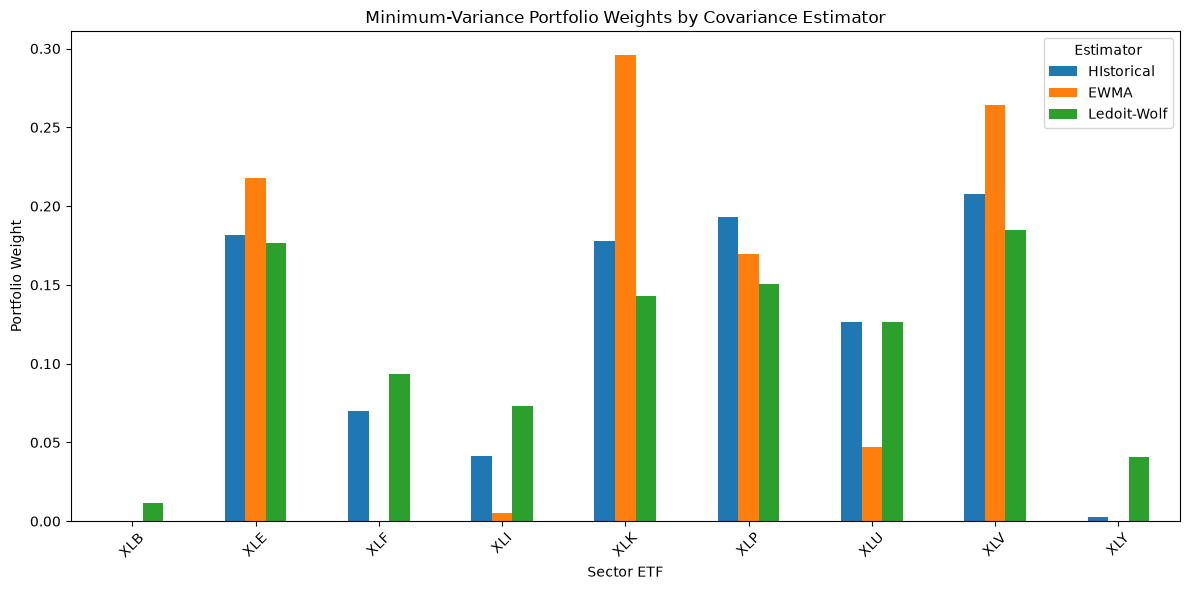

In [320]:
portfolio_weights.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Minimum-Variance Portfolio Weights by Covariance Estimator"
)

plt.xlabel("Sector ETF")
plt.ylabel("Portfolio Weight")
plt.xticks(rotation=45)
plt.legend(title="Estimator")
plt.tight_layout()
plt.show()

In [321]:
def annualised_portfolio_volatility(weights, covariance_matrix):

    daily_variance = portfolio_variance(
        weights,
        np.asarray(covariance_matrix)
    )

    return np.sqrt(
        max(daily_variance, 0.0) * 252
    )

In [322]:
estimated_volatility = pd.Series({
    "Historical": annualised_portfolio_volatility(
        weights_historical,
        cov_last
    ),
    "EWMA": annualised_portfolio_volatility(
        weights_ewma,
        ewma_cov_last
    ),
    "Ledoit-Wolf": annualised_portfolio_volatility(
        weights_shrinkage,
        shrinkage_cov_last
    ),
})

print(
    (estimated_volatility * 100).round(2)
)

Historical     6.63
EWMA           6.04
Ledoit-Wolf    6.63
dtype: float64


In [323]:
def portfolio_concentration(weights):
    return np.sum(np.square(weights))

In [324]:
concentration_comparison = pd.Series({
    "Historical": portfolio_concentration(
        weights_historical
    ),
    "EWMA": portfolio_concentration(
        weights_ewma
    ),
    "Ledoit-Wolf": portfolio_concentration(
        weights_shrinkage
    ),
})

concentration_comparison



Historical     0.167459
EWMA           0.236044
Ledoit-Wolf    0.140249
dtype: float64

In [325]:
for name, weights in {
    "Historical": weights_historical,
    "EWMA": weights_ewma,
    "Ledoit-Wolf": weights_shrinkage
}.items():

    print(f"\n{name}")

    print(
        "Weights sum to 1:",
        np.isclose(weights.sum(), 1.0)
    )

    print(
        "Long-only:",
        np.all(weights >= -1-8)
    )

    print(
        "Finite weights:",
        np.all(np.isfinite(weights))
    )


Historical
Weights sum to 1: True
Long-only: True
Finite weights: True

EWMA
Weights sum to 1: True
Long-only: True
Finite weights: True

Ledoit-Wolf
Weights sum to 1: True
Long-only: True
Finite weights: True


In [326]:
equal_weights = np.ones(9) / 9

for name, weights, covariance in [
    ("Historical", weights_historical, cov_last),
    ("EWMA", weights_ewma, ewma_cov_last),
    ("Ledoit-Wolf", weights_shrinkage, shrinkage_cov_last)
]:

    equal_var = portfolio_variance(
        equal_weights,
        covariance.values
    )

    optimised_var = portfolio_variance(
        weights,
        covariance.values
    )

    print(
        name,
        "Optimised variance <= Equal-weight variance:",
        optimised_var <= equal_var + 1e-10
    )

Historical Optimised variance <= Equal-weight variance: True
EWMA Optimised variance <= Equal-weight variance: True
Ledoit-Wolf Optimised variance <= Equal-weight variance: True


In [327]:
portfolio_weights.to_csv(
    "step21_minimum_variance_weights.csv"
)

estimated_volatility.to_csv(
    "step21_estimated_volatility.csv"
)

concentration_comparison.to_csv(
    "step21_portfolio_concentration.csv"
)

### Minimum-Variance Portfolio Optimisation

A long-only, fully invested global minimum-variance portfolio
optimisation procedure was implemented using SciPy's SLSQP solver.

Portfolio variance was minimised subject to weights summing to one
and individual weights being constrained between zero and one.

The optimisation was applied separately to the Historical, EWMA
and Ledoit-Wolf covariance estimates for the nine sector ETFs.

Resulting portfolio weights were compared in terms of allocation,
estimated annualised volatility and weight concentration.

These single-date comparisons are preliminary diagnostics rather
than evidence of out-of-sample superiority. A subsequent walk-forward
evaluation will assess realised portfolio risk, turnover and
stability using information available at each decision date.

In [331]:

import numpy as np
import pandas as pd
from scipy.optimize import minimize, Bounds, LinearConstraint
from sklearn.covariance import LedoitWolf

LOOKBACK = 252
REBALANCE = 21
TRADING_DAYS = 252
COST_BPS = 10

R = sector_returns.sort_index().astype(float).copy()
R = R.dropna()

assert R.shape[1] == 9
assert R.index.is_unique
assert R.index.is_monotonic_increasing
assert np.isfinite(R.to_numpy()).all()
assert len(R) > LOOKBACK + REBALANCE

def get_covariances(window):
    X = window.to_numpy()

    historical = np.cov(X, rowvar=False, ddof=1)

    # EWMA covariance with lambda = 0.94
    decay = 0.94
    centered = X - X.mean(axis=0)
    weights = decay ** np.arange(len(X)-1, -1, -1)
    weights /= weights.sum()

    ewma = (centered * weights[:, None]).T @ centered

    shrinkage = LedoitWolf().fit(X).covariance_

    static_blend = (
        historical + ewma + shrinkage
    ) / 3

    return {
        "Historical": historical,
        "EWMA": ewma,
        "Ledoit-Wolf": shrinkage,
        "Static Blend": static_blend
    }

def optimise_portfolio(cov):

    cov = np.asarray(cov, dtype=float)
    cov = (cov + cov.T) / 2

    n = cov.shape[0]

    # Check covariance matrix
    if not np.isfinite(cov).all():
        raise ValueError("Covariance contains NaN or infinity")

    # Numerical safeguard for tiny negative eigenvalues
    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    eigenvalues = np.maximum(eigenvalues, 1e-12)

    cov = (eigenvectors * eigenvalues) @ eigenvectors.T

    # Scale objective for numerical stability
    scale = 1 / max(np.max(np.abs(cov)), 1e-12)

    def objective(w):
        return scale * (w @ cov @ w)

    def gradient(w):
        return 2 * scale * (cov @ w)

    initial_weights = np.ones(n) / n

    constraints = [{
        "type": "eq",
        "fun": lambda w: np.sum(w) - 1,
        "jac": lambda w: np.ones(n)
    }]

    result = minimize(
        objective,
        initial_weights,
        jac=gradient,
        method="SLSQP",
        bounds=[(0, 1)] * n,
        constraints=constraints,
        options={
            "ftol": 1e-9,
            "maxiter": 2000
        }
    )

    if not result.success:
        print("SLSQP failed. Trying trust-constr...")

        result = minimize(
            objective,
            initial_weights,
            jac=gradient,
            hess=lambda w: 2 * scale * cov,
            method="trust-constr",
            bounds=Bounds(
                np.zeros(n),
                np.ones(n)
            ),
            constraints=LinearConstraint(
                np.ones((1, n)),
                [1.0],
                [1.0]
            ),
            options={
                "maxiter": 2000,
                "gtol": 1e-9,
                "xtol": 1e-9,
                "verbose": 0
            }
        )

    if not result.success:
        raise RuntimeError(
            f"Portfolio optimisation failed: {result.message}"
        )

    weights = result.x

    if (
        np.any(weights < -1e-6)
        or np.any(weights > 1 + 1e-6)
        or not np.isclose(weights.sum(), 1, atol=1e-6)
    ):
        raise RuntimeError("Invalid portfolio weights")

    return weights



In [332]:

test_window = R.iloc[:LOOKBACK]

test_covariances = get_covariances(test_window)

for name, cov in test_covariances.items():

    weights = optimise_portfolio(cov)

    print(f"\n{name}")
    print("Weights:", np.round(weights, 4))
    print("Sum:", weights.sum())
    print("Minimum weight:", weights.min())
    print("Portfolio variance:", weights @ cov @ weights)



Historical
Weights: [0.    0.    0.    0.    0.    0.963 0.037 0.    0.   ]
Sum: 1.0000000000000007
Minimum weight: 0.0
Portfolio variance: 5.802458521268842e-05

EWMA
Weights: [0.     0.     0.     0.     0.     0.5882 0.4118 0.     0.    ]
Sum: 1.0000000000000004
Minimum weight: 0.0
Portfolio variance: 1.7329259078724575e-05

Ledoit-Wolf
Weights: [0.     0.     0.     0.     0.     0.8539 0.0905 0.0556 0.    ]
Sum: 1.0
Minimum weight: 0.0
Portfolio variance: 5.9251114060743807e-05

Static Blend
Weights: [0.     0.     0.     0.     0.     0.8657 0.1343 0.     0.    ]
Sum: 1.0000000000000002
Minimum weight: 0.0
Portfolio variance: 4.541541019839885e-05


In [333]:

strategies = [
    "Historical", "EWMA",
    "Ledoit-Wolf", "Static Blend", "Equal Weight"
]

return_log = {s: [] for s in strategies}
turnover_log = {s: [] for s in strategies}
weight_log = {s: [] for s in strategies}

# Track post-drift portfolio weights between rebalances
previous_weights = {s: None for s in strategies}

for t in range(LOOKBACK, len(R), REBALANCE):

    train = R.iloc[t - LOOKBACK:t]
    test = R.iloc[t:t + REBALANCE]

    covariance_models = get_covariances(train)

    targets = {
        name: optimise_portfolio(cov)
        for name, cov in covariance_models.items()
    }

    targets["Equal Weight"] = (
        np.ones(R.shape[1]) / R.shape[1]
    )

    for name, target in targets.items():

        previous = previous_weights[name]

        turnover = (
            0.0 if previous is None
            else np.abs(target - previous).sum()
        )

        cost = turnover * COST_BPS / 10000
        turnover_log[name].append(turnover)
        weight_log[name].append(
            (test.index[0], target.copy())
        )

        # Start with target holdings after rebalance
        holdings = target.copy()
        first_day = True

        for date, row in test.iterrows():

            gross = holdings * (1 + row.to_numpy())
            gross_return = gross.sum() - 1

            # Deduct trading cost on first day
            if first_day:
                net_return = (
                    (1 - cost) * (1 + gross_return) - 1
                )
                first_day = False
            else:
                net_return = gross_return

            return_log[name].append((date, net_return))

            # Allow portfolio weights to drift
            holdings = gross / gross.sum()

        previous_weights[name] = holdings.copy()

backtest_returns = pd.DataFrame({
    name: pd.Series(dict(return_log[name]))
    for name in strategies
}).sort_index()

print(backtest_returns.head())
print(backtest_returns.shape)

assert backtest_returns.notna().all().all()
assert backtest_returns.index.is_unique


            Historical      EWMA  Ledoit-Wolf  Static Blend  Equal Weight
2011-01-04   -0.002452  0.000352    -0.001726     -0.001724     -0.001610
2011-01-05    0.000093 -0.002422    -0.000163     -0.000562      0.003688
2011-01-06   -0.003259 -0.001619    -0.002606     -0.002833     -0.002413
2011-01-07   -0.004832 -0.001583    -0.004113     -0.003988     -0.000899
2011-01-10    0.000460 -0.001839    -0.000067     -0.000139     -0.001252
(3966, 5)


In [334]:

def calculate_metrics(r, turnover):
    r = r.dropna()
    wealth = (1 + r).cumprod()

    annual_vol = r.std() * np.sqrt(252)

    sharpe = (
        r.mean() / r.std() * np.sqrt(252)
        if r.std() > 0 else np.nan
    )

    drawdown = wealth / wealth.cummax() - 1

    return {
        "Realised Volatility": annual_vol,
        "Annualised Return": wealth.iloc[-1] ** (252 / len(r)) - 1,
        "Sharpe (Rf=0)": sharpe,
        "Maximum Drawdown": drawdown.min(),
        "Average Turnover": np.mean(turnover)
    }

results = pd.DataFrame({
    s: calculate_metrics(
        backtest_returns[s],
        turnover_log[s]
    )
    for s in strategies
}).T

display(results.round(4))

print(
    "Lowest realised volatility:",
    results["Realised Volatility"].idxmin()
)


,Realised Volatility,Annualised Return,Sharpe (Rf=0),Maximum Drawdown,Average Turnover
Historical,0.1340,0.0903,0.7125,-0.3457,0.1309
EWMA,0.1320,0.0769,0.6272,-0.2951,0.6744
Ledoit-Wolf,0.1340,0.0956,0.7486,-0.3466,0.1222
Static Blend,0.1313,0.0854,0.6902,-0.3097,0.2884
Equal Weight,0.1626,0.1036,0.6880,-0.3922,0.0245


Lowest realised volatility: Static Blend


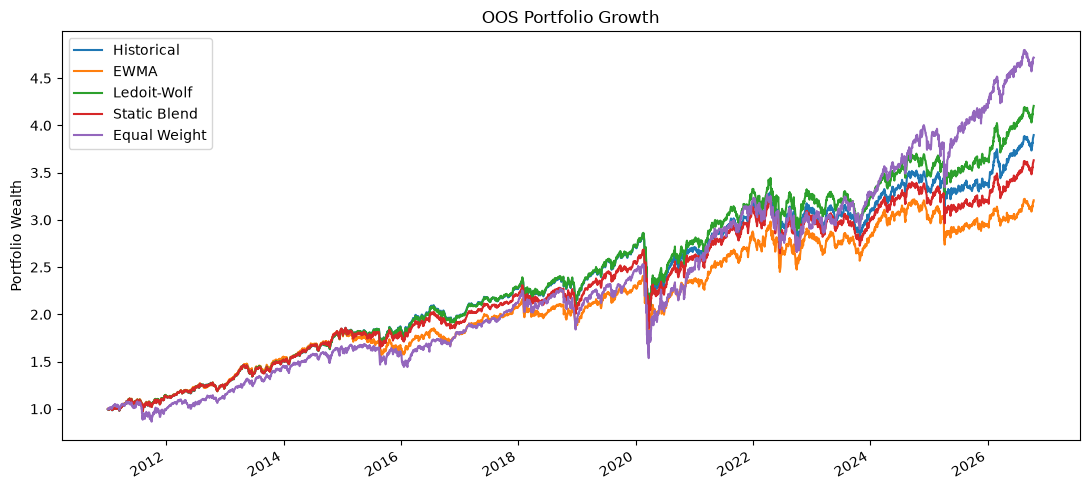

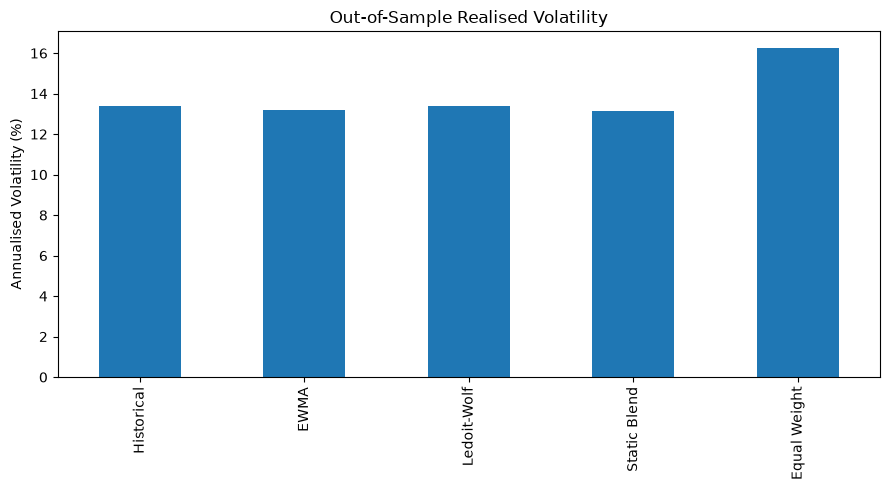

In [335]:

import matplotlib.pyplot as plt

equity = (1 + backtest_returns).cumprod()

equity.plot(figsize=(11, 5), title="OOS Portfolio Growth")
plt.ylabel("Portfolio Wealth")
plt.tight_layout()
plt.savefig("portfolio_growth.png", dpi=200)
plt.show()

(results["Realised Volatility"] * 100).plot(
    kind="bar", figsize=(9, 5),
    title="Out-of-Sample Realised Volatility"
)
plt.ylabel("Annualised Volatility (%)")
plt.tight_layout()
plt.savefig("volatility_comparison.png", dpi=200)
plt.show()

results.to_csv("portfolio_results.csv")
backtest_returns.to_csv("oos_returns.csv")


In [ ]:

import numpy as np
import pandas as pd

# Align market indicators to the sector ETF trading calendar
spy = spy_price.reindex(R.index).ffill()
vix = vix.reindex(R.index).ffill()

# SPY daily simple returns
spy_returns = spy.pct_change()

# Construct market-state features
market_features = pd.DataFrame(index=R.index)

market_features["VIX"] = vix

market_features["SPY_21D_VOL"] = (
    spy_returns.rolling(21).std() * np.sqrt(252)
)

market_features["SPY_21D_RETURN"] = (
    spy.pct_change(21)
)

market_features["VIX_5D_CHANGE"] = (
    vix.pct_change(5, fill_method=None)
)

# One-day lag prevents using today's closing values
# to make a decision at the beginning of today
market_features = market_features.shift(1)

display(market_features.tail())
print(market_features.isna().sum())
